# 🏦 Modèle de notation interne (SNI) : qualité des données, traitement et sélection des variables

**Objectif** : construire un modèle de notation interne des clients particuliers d'une banque, de la qualité des données jusqu'à l'échelle de probabilité de défaut (PD) :

| Partie | Contenu | Livrable |
|---|---|---|
| **1. Contrôle de la qualité des données** | doublons, valeurs manquantes, types, incohérences, création de la cible | ce notebook (rapport) |
| **2. Traitement des variables** | séparation train/test, imputation, normalisation, discrétisation, rééchantillonnage | Excel : bases train/test, base rééchantillonnée |
| **3. Sélection des variables** | Information Value (IV) par variable, étude de dépendance | Excel : IV par variable, dépendances |
| **4. Modélisation et PD** | régression logistique, performance (AUC, Gini, KS), grille de score, échelle PD | notebook + Excel |

**Cible** : `flag_defaut = 1` si le client a plus de 90 jours d'impayés sur 12 mois (`DPD 12M ≥ 90`), 0 sinon.

**Convention** : un « mauvais » est un client en défaut (`flag_defaut = 1`), un « bon » un client sain.

## Sommaire
- **Partie 1 — Contrôle de la qualité des données**
  1. Chargement et structure de la base
  2. Doublons
  3. Création de la variable cible
  4. Types de variables
  5. Valeurs manquantes
  6. Incohérences et valeurs aberrantes
  7. Synthèse et plan de traitement
- **Partie 2 — Traitement des variables**
  8. Séparation train / test (par client)
  9. Corrections, imputation et regroupements
  10. Normalisation
  11. Discrétisation
  12. Rééchantillonnage
- **Partie 3 — Sélection des variables**
  13. Information Value
  14. Étude de dépendance
  15. Variables retenues
- **Partie 4 — Modélisation et probabilité de défaut**
  16. Codage WOE
  17. Sélection pas à pas des variables du modèle
  18. Modèle final (régression logistique)
  19. Performance sur la base test
  20. Interprétation des coefficients
  21. Grille de notation (score)
  22. Échelle PD finale
- **Export Excel et conclusion**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# --- Paramètres ---------------------------------------------------------------
DATA_FILE = Path("data/base_SNI.xlsx")
SHEET = "base_sni"
SEUIL_DEFAUT = 90          # jours d'impayés définissant le défaut
TEST_SIZE = 0.30           # 70 % train / 30 % test
RANDOM_STATE = 42          # reproductibilité des tirages aléatoires

MAX_BINS = 3               # nombre maximal de classes par variable continue (hors classe « Manquant »)
MIN_BIN_SHARE = 0.15       # effectif minimal d'une classe : 15 % de la base train ≈ 10 défauts attendus
RARE_SHARE = 0.05          # modalités < 5 % regroupées dans « Autres »
TAUX_CIBLE_RESAMPLING = 0.5  # taux de défaut visé après rééchantillonnage

IV_MIN = 0.02              # IV minimale pour qu'une variable soit jugée prédictive
IV_SUSPECT = 0.5           # au-delà : pouvoir prédictif suspect, à vérifier
CRAMER_MAX = 0.5           # au-delà : deux variables sont jugées redondantes
ALPHA = 0.05               # seuil de significativité du test du χ² variable / défaut

OUTPUT_DIR, FIGURES = Path("outputs"), Path("figures")
for folder in (OUTPUT_DIR, FIGURES):
    folder.mkdir(exist_ok=True)

# --- Style des graphiques -----------------------------------------------------
BLUE, ORANGE, GREY, INK, INK_2 = "#2a78d6", "#eb6834", "#b4b2ab", "#0b0b0b", "#52514e"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
                     "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

---
# Partie 1 — Contrôle de la qualité des données

## 1. Chargement et structure de la base

In [2]:
raw = pd.read_excel(DATA_FILE, sheet_name=SHEET)
print(f"{raw.shape[0]} lignes × {raw.shape[1]} colonnes")
print(f"{raw['code_client'].nunique()} clients distincts, "
      f"observés au {', '.join(sorted(raw['date OBSERVATION'].dt.strftime('%d/%m/%Y').unique()))}")
obs_per_client = raw.drop_duplicates().groupby("code_client").size().value_counts().sort_index()
print("Nombre d'années d'observation par client :", obs_per_client.to_dict())
raw.head()

5752 lignes × 29 colonnes
2289 clients distincts, observés au 31/12/2018, 31/12/2019, 31/12/2020, 31/12/2021
Nombre d'années d'observation par client : {1: 652, 2: 515, 3: 445, 4: 677}


,id_tiers,code_client,CRD,PNU,nb_pret,Maturite,Garantie_max,flag_lombard_decouvert,DPD 12M,Pays de domiciliation,Etat civil,Nationalité,Profession,Segmentation commercilale,Type de revenu,Catégorie sociale,Code tribunal,Code localité,Interdiction cheque,Segment,date OBSERVATION,Age_relation,Date_naissance,Solde_moyen,Revenus_mensuels,Solde_arrete,Engagement,CRD/gar,CRD/eng
0,10231_2018,10231,3877.51,54792.50,1,-58,109585.0,1,0,France,Marié,Morocco,INGENIEUR,Indéterminé (S0),NaN,"Cadres administratifs supérieurs sans responsabilité hiérarchique et cadres commerciaux, financiers et de gestion (17)",NaN,CASABLANCA (780),NaN,Retail GOLD (08),2018-12-31,154,1963-01-14,NaN,NaN,-3877.510000,54792.50,0.035384,0.070767
1,10231_2019,10231,8087.98,45936.25,1,-59,0.0,1,0,France,Marié,Morocco,INGENIEUR,Indéterminé (S0),NaN,"Cadres administratifs supérieurs sans responsabilité hiérarchique et cadres commerciaux, financiers et de gestion (17)",NaN,CASABLANCA (780),NaN,Retail GOLD (08),2019-12-31,166,1963-01-14,NaN,NaN,-8115.410000,45936.25,1.000000,0.176070
2,10231_2020,10231,11702.36,45000.00,1,-60,0.0,1,0,France,Marié,Morocco,INGENIEUR,Indéterminé (S0),NaN,"Cadres administratifs supérieurs sans responsabilité hiérarchique et cadres commerciaux, financiers et de gestion (17)",NaN,CASABLANCA (780),NaN,Retail GOLD (08),2020-12-31,178,1963-01-15,NaN,NaN,-8115.410000,45000.00,1.000000,0.260052
3,10231_2021,10231,328.53,53085.75,1,-61,0.0,1,0,France,Marié,Morocco,INGENIEUR,Indéterminé (S0),NaN,"Cadres administratifs supérieurs sans responsabilité hiérarchique et cadres commerciaux, financiers et de gestion (17)",NaN,CASABLANCA (780),NaN,Retail GOLD (08),2021-12-31,190,1963-01-15,NaN,NaN,-328.530000,53085.75,1.000000,0.006189
4,10261_2018,10261,1277030.69,0.00,1,18,2475000.0,0,0,Morocco,Marié,Morocco,CADRE BQ,Indéterminé (S0),NaN,"Cadres administratifs supérieurs sans responsabilité hiérarchique et cadres commerciaux, financiers et de gestion (17)",NaN,CASABLANCA (780),NaN,"Private customer, universal (01)",2018-12-31,154,1978-01-10,NaN,NaN,78611.768604,2650000.00,0.515972,0.481898


La base est un **panel** : chaque ligne est un couple *client × date d'observation* (fin d'année 2018 à 2021), identifié par `id_tiers = code_client_année`. Un même client apparaît jusqu'à 4 fois. Cette structure a deux conséquences :
- les doublons se contrôlent sur `id_tiers` ;
- la séparation train/test devra se faire **par client** (partie 2), sinon un client pourrait être à la fois dans la base d'apprentissage et dans la base de test.

## 2. Doublons

In [3]:
exact_dup = raw.duplicated()
id_dup = raw.duplicated("id_tiers", keep=False)
print(f"Lignes strictement identiques à une ligne précédente : {exact_dup.sum()}")
print(f"Lignes dont l'identifiant id_tiers apparaît plusieurs fois : {id_dup.sum()}")

df = raw.drop_duplicates().reset_index(drop=True)
print(f"\nAprès suppression des doublons exacts : {len(df)} lignes, "
      f"identifiant id_tiers unique : {df['id_tiers'].is_unique}")
raw.loc[exact_dup, "id_tiers"].value_counts().rename("copies supprimées").to_frame().T

Lignes strictement identiques à une ligne précédente : 27
Lignes dont l'identifiant id_tiers apparaît plusieurs fois : 50

Après suppression des doublons exacts : 5725 lignes, identifiant id_tiers unique : True


id_tiers,963_2021,10261_2018,10261_2019,10261_2020,10261_2021,10277_2018,10277_2019,866_2021,874_2018,874_2019,874_2020,874_2021,910_2019,910_2020,910_2021,923_2018,923_2019,923_2020,923_2021,926_2018,926_2019,926_2020,926_2021
copies supprimées,5,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


Les 27 doublons sont des **copies exactes** (toutes les colonnes identiques) : on les supprime. Après suppression, `id_tiers` est bien une clé unique.

## 3. Création de la variable cible

In [4]:
df["flag_defaut"] = (df["DPD 12M"] >= SEUIL_DEFAUT).astype(int)
df["annee"] = df["date OBSERVATION"].dt.year

summary_target = df.groupby("annee")["flag_defaut"].agg(observations="size", defauts="sum", taux="mean")
summary_target.loc["Total"] = [len(df), df.flag_defaut.sum(), df.flag_defaut.mean()]
summary_target["taux"] = (summary_target["taux"] * 100).round(2).astype(str) + " %"
print(f"Clients ayant fait défaut au moins une fois : {df.groupby('code_client').flag_defaut.max().sum()}")
summary_target

Clients ayant fait défaut au moins une fois : 63


,observations,defauts,taux
annee,,,
2018,773.0,21.0,2.72 %
2019,1176.0,21.0,1.79 %
2020,1622.0,27.0,1.66 %
2021,2154.0,48.0,2.23 %
Total,5725.0,117.0,2.04 %


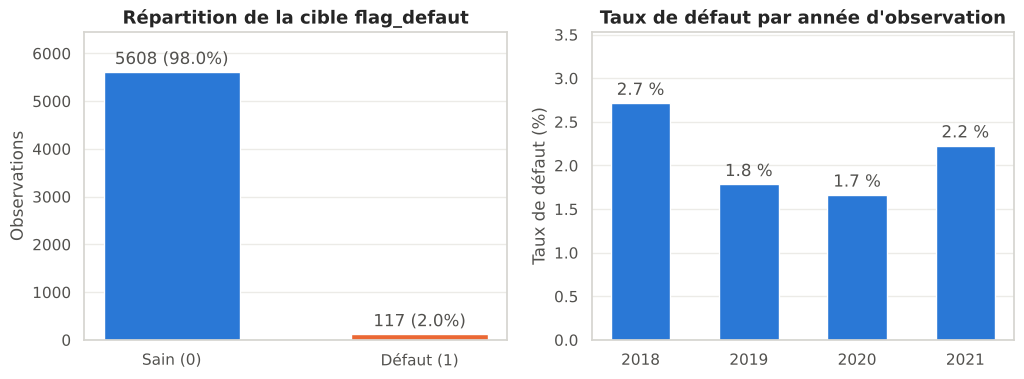

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df["flag_defaut"].value_counts().sort_index()
bars = axes[0].bar(["Sain (0)", "Défaut (1)"], counts.values, color=[BLUE, ORANGE], width=0.55)
axes[0].bar_label(bars, labels=[f"{v} ({v / len(df):.1%})" for v in counts.values], padding=3, color=INK_2)
axes[0].set(title="Répartition de la cible flag_defaut", ylabel="Observations", ylim=(0, counts.max() * 1.15))
rate = df.groupby("annee")["flag_defaut"].mean() * 100
bars = axes[1].bar(rate.index.astype(str), rate.values, color=BLUE, width=0.55)
axes[1].bar_label(bars, fmt="%.1f %%", padding=3, color=INK_2)
axes[1].set(title="Taux de défaut par année d'observation", ylabel="Taux de défaut (%)", ylim=(0, rate.max() * 1.3))
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "01_cible.png")
plt.show()

**Taux de défaut ≈ 2 %** : la cible est **fortement déséquilibrée** (environ 1 défaut pour 48 clients sains). Un modèle qui prédirait toujours « sain » aurait 98 % de bonnes réponses sans aucune utilité : d'où l'étape de rééchantillonnage (section 12) et le choix de métriques adaptées (AUC, Gini) pour la modélisation.

⚠️ La variable `DPD 12M` sert à **définir** la cible : elle est **exclue des variables explicatives**, sinon le modèle « connaîtrait la réponse » (fuite d'information).

## 4. Types de variables

In [6]:
ROLES = {
    "id_tiers": "identifiant", "code_client": "identifiant",
    "DPD 12M": "source de la cible (exclue)", "flag_defaut": "cible",
    "date OBSERVATION": "date (contexte)", "annee": "date (contexte)",
    "Date_naissance": "date → âge",
}
types = pd.DataFrame({
    "type pandas": df.dtypes.astype(str),
    "valeurs distinctes": df.nunique(),
    "exemple": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
types["nature"] = [
    ROLES.get(c, "quantitative" if pd.api.types.is_numeric_dtype(df[c]) else "qualitative")
    for c in df.columns
]
types.sort_values("nature")

,type pandas,valeurs distinctes,exemple,nature
flag_defaut,int64,2,0,cible
annee,int32,4,2018,date (contexte)
date OBSERVATION,datetime64[us],4,2018-12-31 00:00:00,date (contexte)
Date_naissance,datetime64[us],114,1963-01-14 00:00:00,date → âge
id_tiers,str,5725,10231_2018,identifiant
code_client,int64,2289,10231,identifiant
Code localité,str,38,CASABLANCA (780),qualitative
Segment,str,6,Retail GOLD (08),qualitative
Interdiction cheque,str,1,Interdiction bancaire (01),qualitative
Code tribunal,str,6,CASABLANCA (81),qualitative


Remarques sur les types :
- `flag_lombard_decouvert` est présenté comme un indicateur, mais prend les valeurs 0 à 4 : c'est un **nombre** (de facilités lombard/découvert). On le traite comme une variable quantitative discrète.
- `Age_relation` augmente de 12 par an pour un même client : c'est une ancienneté de la relation bancaire **en mois**.
- `Date_naissance` n'est pas utilisable telle quelle : on en dérive l'**âge à la date d'observation**.
- `Maturite` est une durée résiduelle (en mois) qui prend des valeurs négatives (section 6).

## 5. Valeurs manquantes

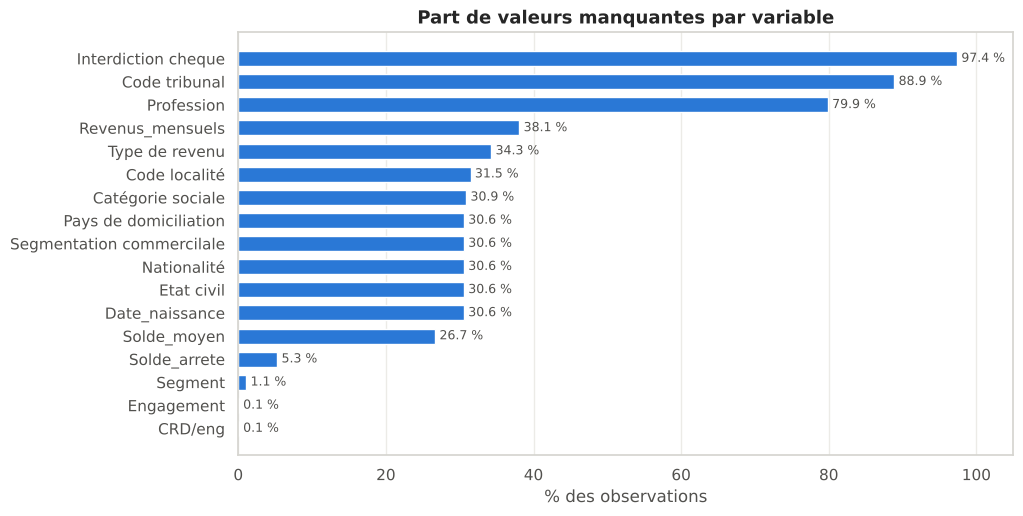

,manquants,% manquants
Interdiction cheque,5578,97.4
Code tribunal,5092,88.9
Profession,4577,79.9
Revenus_mensuels,2183,38.1
Type de revenu,1963,34.3
Code localité,1805,31.5
Catégorie sociale,1771,30.9
Pays de domiciliation,1749,30.6
Segmentation commercilale,1749,30.6
Nationalité,1749,30.6


In [7]:
missing = pd.DataFrame({"manquants": df.isna().sum(), "% manquants": (df.isna().mean() * 100).round(1)})
missing = missing[missing["manquants"] > 0].sort_values("% manquants", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(missing.index[::-1], missing["% manquants"][::-1], color=BLUE, height=0.65)
ax.bar_label(bars, fmt="%.1f %%", padding=3, color=INK_2, fontsize=9)
ax.set(title="Part de valeurs manquantes par variable", xlabel="% des observations", xlim=(0, 105))
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "02_valeurs_manquantes.png")
plt.show()
missing

In [8]:
socio = ["Pays de domiciliation", "Etat civil", "Nationalité", "Segmentation commercilale", "Date_naissance"]
bloc = df[socio].isna().all(axis=1)
print(f"Lignes où les 5 variables sociodémographiques sont TOUTES manquantes : {bloc.sum()}")
print(f"Lignes où au moins une est manquante                                : {df[socio].isna().any(axis=1).sum()}")

miss_vs_target = pd.DataFrame({
    var: df.groupby(df[var].isna())["flag_defaut"].mean().rename({False: "renseigné", True: "manquant"}) * 100
    for var in ["Revenus_mensuels", "Solde_moyen", "Date_naissance", "Type de revenu", "Interdiction cheque", "Code tribunal"]
}).T.round(2)
miss_vs_target.columns = [f"taux de défaut si {c} (%)" for c in miss_vs_target.columns]
miss_vs_target

Lignes où les 5 variables sociodémographiques sont TOUTES manquantes : 1749
Lignes où au moins une est manquante                                : 1749


,taux de défaut si renseigné (%),taux de défaut si manquant (%)
Revenus_mensuels,1.75,2.52
Solde_moyen,1.79,2.75
Date_naissance,2.14,1.83
Type de revenu,1.99,2.14
Interdiction cheque,15.65,1.69
Code tribunal,3.63,1.85


**Lecture** :
- Les valeurs manquantes des variables sociodémographiques ne sont **pas dispersées au hasard** : un même bloc de ~1 750 lignes (30 %) n'a **aucune** information sociodémographique. Il s'agit vraisemblablement de clients dont la fiche n'a pas été reprise dans le système source.
- Le fait d'être manquant **est parfois lui-même informatif** : par exemple, le taux de défaut est plus élevé quand le revenu n'est pas renseigné. Remplacer ces valeurs par une moyenne ferait perdre cette information.
- Deux variables ont des manquants **structurels** :
  - `Interdiction cheque` n'est renseignée que pour les clients interdits bancaires → manquant = « pas d'interdiction » ;
  - `Code tribunal` n'est renseigné que pour une minorité de clients (11 %) → on retient l'indicateur « code tribunal renseigné (Oui/Non) », associé à un taux de défaut deux fois plus élevé.
- `Profession` est manquante à 80 % et compte 354 libellés libres : elle est **inexploitable** et sera supprimée (l'information est en partie couverte par `Catégorie sociale`).

## 6. Incohérences et valeurs aberrantes

In [9]:
age = (df["date OBSERVATION"] - df["Date_naissance"]).dt.days / 365.25
ratio_gar = df["CRD"] / df["Garantie_max"].replace(0, np.nan)

anomalies = pd.DataFrame([
    ("Âge < 18 ans à la date d'observation", (age < 18).sum(),
     "Dates de naissance au 01/01/2020 : valeur par défaut du système → âge mis à manquant"),
    ("CRD/gar = 1 alors que Garantie_max = 0", ((df["Garantie_max"] == 0) & (df["CRD/gar"] == 1)).sum(),
     "Ratio indéfini codé arbitrairement à 1 → ratio recalculé, classe « Sans garantie »"),
    ("CRD/gar > 1 avec une garantie > 0", ((df["Garantie_max"] > 0) & (ratio_gar > 1)).sum(),
     "Encours supérieur à la garantie : plausible (sous-couverture), conservé"),
    ("CRD/eng recalculé ≠ CRD/eng fourni", ((df["CRD"] / df["Engagement"] - df["CRD/eng"]).abs() > 1e-6).sum(),
     "Cohérent : aucune correction nécessaire"),
    ("Engagement inférieur au CRD (CRD/eng > 1)", (df["CRD/eng"] > 1).sum(),
     "Encours supérieur au montant engagé (intérêts, impayés) : conservé"),
    ("Maturite < 0 (échéance dépassée)", (df["Maturite"] < 0).sum(),
     "Concentré entre -61 et -58 mois : prêts arrivés à échéance mais encore en cours, conservé (informatif)"),
    ("Revenus_mensuels = 0", (df["Revenus_mensuels"] == 0).sum(),
     "Revenu nul déclaré pour un emprunteur : valeur non renseignée → mis à manquant"),
    ("flag_lombard_decouvert > 1", (df["flag_lombard_decouvert"] > 1).sum(),
     "Ce n'est pas un indicateur 0/1 mais un nombre : traité comme quantitatif"),
    ("Soldes négatifs (Solde_arrete < 0)", (df["Solde_arrete"] < 0).sum(),
     "Comptes débiteurs (découvert) : plausible, conservé"),
], columns=["contrôle", "observations concernées", "décision"])
anomalies

,contrôle,observations concernées,décision
0,Âge < 18 ans à la date d'observation,6,Dates de naissance au 01/01/2020 : valeur par défaut du système → âge mis à manquant
1,CRD/gar = 1 alors que Garantie_max = 0,1476,"Ratio indéfini codé arbitrairement à 1 → ratio recalculé, classe « Sans garantie »"
2,CRD/gar > 1 avec une garantie > 0,744,"Encours supérieur à la garantie : plausible (sous-couverture), conservé"
3,CRD/eng recalculé ≠ CRD/eng fourni,0,Cohérent : aucune correction nécessaire
4,Engagement inférieur au CRD (CRD/eng > 1),506,"Encours supérieur au montant engagé (intérêts, impayés) : conservé"
5,Maturite < 0 (échéance dépassée),727,"Concentré entre -61 et -58 mois : prêts arrivés à échéance mais encore en cours, conservé (informatif)"
6,Revenus_mensuels = 0,13,Revenu nul déclaré pour un emprunteur : valeur non renseignée → mis à manquant
7,flag_lombard_decouvert > 1,22,Ce n'est pas un indicateur 0/1 mais un nombre : traité comme quantitatif
8,Soldes négatifs (Solde_arrete < 0),509,"Comptes débiteurs (découvert) : plausible, conservé"


In [10]:
NUMERIC_RAW = ["CRD", "PNU", "nb_pret", "Maturite", "Garantie_max", "flag_lombard_decouvert",
               "Age_relation", "Solde_moyen", "Revenus_mensuels", "Solde_arrete", "Engagement", "CRD/gar", "CRD/eng"]
desc = df[NUMERIC_RAW].describe(percentiles=[0.01, 0.5, 0.99]).T
desc["max / p99"] = (desc["max"] / desc["99%"]).replace([np.inf, -np.inf], np.nan).round(1)
desc[["min", "1%", "50%", "99%", "max", "max / p99"]].round(2)

,min,1%,50%,99%,max,max / p99
CRD,0.00,0.00,953321.58,8919951.19,1.060000e+08,11.9
PNU,0.00,0.00,0.00,3229145.28,7.698238e+07,23.8
nb_pret,1.00,1.00,1.00,4.00,1.300000e+01,3.2
Maturite,-61.00,-61.00,13.00,21.00,2.500000e+01,1.2
Garantie_max,0.00,0.00,900000.00,10429866.54,2.157835e+08,20.7
flag_lombard_decouvert,0.00,0.00,0.00,1.00,4.000000e+00,4.0
Age_relation,0.00,0.00,29.00,272.76,3.110000e+02,1.1
Solde_moyen,-3043288.18,-51071.85,16498.90,1057843.48,8.215673e+06,7.8
Revenus_mensuels,0.00,3457.25,27000.00,172367.92,3.088967e+05,1.8
Solde_arrete,-35157500.28,-763807.12,29540.15,1684907.41,2.853975e+07,16.9


Plusieurs montants ont des valeurs **extrêmes** (le maximum dépasse largement le 99ᵉ centile, par exemple pour `CRD`, `PNU`, `Garantie_max` ou `Solde_arrete`). Ce ne sont pas forcément des erreurs (gros clients patrimoniaux), mais ils écraseraient une moyenne ou une normalisation. Traitement retenu :
- pour la **discrétisation**, aucune correction n'est nécessaire : les valeurs extrêmes tombent simplement dans la dernière classe ;
- pour la **version normalisée**, les valeurs sont **plafonnées aux 1ᵉʳ et 99ᵉ centiles** de la base d'apprentissage (*winsorisation*) avant standardisation.

## 7. Synthèse et plan de traitement

In [11]:
plan = pd.DataFrame([
    ("id_tiers, code_client", "Identifiants", "Exclus des variables explicatives (code_client sert au découpage train/test)"),
    ("DPD 12M", "Source de la cible", "Exclue (fuite d'information)"),
    ("date OBSERVATION", "Date", "Sert au calcul de l'âge et aux contrôles de stabilité"),
    ("Date_naissance", "Date", "Remplacée par l'âge à l'observation ; âges < 18 ans mis à manquant"),
    ("Profession", "Qualitative", "Supprimée : 80 % de manquants, 354 libellés libres"),
    ("Interdiction cheque", "Qualitative", "Manquant structurel → « Non »"),
    ("Code tribunal", "Qualitative", "Remplacée par l'indicateur « code tribunal renseigné » (Oui/Non)"),
    ("Pays de domiciliation, Nationalité", "Qualitatives", "Regroupées en Maroc / Étranger / Non renseigné"),
    ("Autres qualitatives", "Qualitatives", "Manquant → « Non renseigné » ; modalités < 5 % regroupées en « Autres »"),
    ("CRD/gar", "Quantitative", "Recalculée ; garantie nulle → classe « Sans garantie »"),
    ("Revenus_mensuels", "Quantitative", "Valeurs 0 → manquant ; manquants gardés en classe « Manquant »"),
    ("Quantitatives peu manquantes (< 5 %)", "Quantitatives", "Imputation par la médiane de la base d'apprentissage"),
    ("Quantitatives très manquantes (> 5 %)", "Quantitatives", "Classe « Manquant » lors de la discrétisation (le manquant est informatif)"),
    ("Toutes les quantitatives", "Quantitatives", "Discrétisation supervisée (arbre de décision) ; version normalisée en complément"),
    ("Nouvelle variable", "Quantitative", "Taux d'engagement = Engagement / (12 × Revenus mensuels)"),
], columns=["variable(s)", "nature", "traitement"])
plan

,variable(s),nature,traitement
0,"id_tiers, code_client",Identifiants,Exclus des variables explicatives (code_client sert au découpage train/test)
1,DPD 12M,Source de la cible,Exclue (fuite d'information)
2,date OBSERVATION,Date,Sert au calcul de l'âge et aux contrôles de stabilité
3,Date_naissance,Date,Remplacée par l'âge à l'observation ; âges < 18 ans mis à manquant
4,Profession,Qualitative,"Supprimée : 80 % de manquants, 354 libellés libres"
5,Interdiction cheque,Qualitative,Manquant structurel → « Non »
6,Code tribunal,Qualitative,Remplacée par l'indicateur « code tribunal renseigné » (Oui/Non)
7,"Pays de domiciliation, Nationalité",Qualitatives,Regroupées en Maroc / Étranger / Non renseigné
8,Autres qualitatives,Qualitatives,Manquant → « Non renseigné » ; modalités < 5 % regroupées en « Autres »
9,CRD/gar,Quantitative,Recalculée ; garantie nulle → classe « Sans garantie »


---
# Partie 2 — Traitement des variables

## 8. Séparation train / test (par client)

Toutes les règles de traitement (médianes, bornes, classes) sont **apprises sur la base d'apprentissage seulement**, puis appliquées telles quelles à la base de test. La séparation est donc faite **avant** l'imputation et la discrétisation : sinon, des informations de la base de test seraient utilisées pour construire le modèle, ce qui surestimerait ses performances.

Méthode :
- tirage **par client** (tous les millésimes d'un même client vont dans la même base) ;
- **stratifié** sur le fait d'avoir fait défaut au moins une fois, pour retrouver le même taux de défaut dans les deux bases ;
- proportions 70 % / 30 %.

In [12]:
clients = df.groupby("code_client")["flag_defaut"].max()
train_clients, test_clients = train_test_split(
    clients.index, test_size=TEST_SIZE, stratify=clients.values, random_state=RANDOM_STATE)

train_raw = df[df["code_client"].isin(train_clients)].copy()
test_raw = df[df["code_client"].isin(test_clients)].copy()

split_summary = pd.DataFrame({
    base: {"clients": d["code_client"].nunique(), "observations": len(d),
           "% des observations": round(len(d) / len(df) * 100, 1),
           "défauts": int(d["flag_defaut"].sum()), "taux de défaut (%)": round(d["flag_defaut"].mean() * 100, 2)}
    for base, d in [("Train", train_raw), ("Test", test_raw), ("Total", df)]
}).T
print("Aucun client commun aux deux bases :", set(train_clients).isdisjoint(test_clients))
print("flag_defaut présent dans les deux bases :", "flag_defaut" in train_raw and "flag_defaut" in test_raw)
split_summary

Aucun client commun aux deux bases : True
flag_defaut présent dans les deux bases : True


,clients,observations,% des observations,défauts,taux de défaut (%)
Train,1602.0,4033.0,70.4,76.0,1.88
Test,687.0,1692.0,29.6,41.0,2.42
Total,2289.0,5725.0,100.0,117.0,2.04


In [13]:
by_year = pd.concat({
    "Train": train_raw.groupby("annee")["flag_defaut"].agg(["size", "mean"]),
    "Test": test_raw.groupby("annee")["flag_defaut"].agg(["size", "mean"]),
}, axis=1)
by_year.columns = [f"{base} — {'observations' if m == 'size' else 'taux de défaut'}" for base, m in by_year.columns]
by_year.iloc[:, [1, 3]] = (by_year.iloc[:, [1, 3]] * 100).round(2)
by_year

,Train — observations,Train — taux de défaut,Test — observations,Test — taux de défaut
annee,,,,
2018,549,2.19,224,4.02
2019,836,1.79,340,1.76
2020,1146,1.57,476,1.89
2021,1502,2.06,652,2.61


Les deux bases ont des taux de défaut proches (≈ 1,9 % en train contre ≈ 2,4 % en test) et la même répartition par année. L'écart restant s'explique par le faible nombre de défauts : avec une quarantaine de défauts en test, quelques clients suffisent à faire varier le taux. La stratification par client garantit que les défauts sont répartis dans les mêmes proportions que les clients.

## 9. Corrections, imputation et regroupements

In [14]:
def short_label(text, width=38):
    """Raccourcit les libellés longs en conservant le code entre parenthèses."""
    if pd.isna(text):
        return text
    text = " ".join(str(text).split())
    code_part = text[text.rfind("("):] if text.endswith(")") else ""
    body = text[: len(text) - len(code_part)].strip()
    return f"{body[:width].rstrip()}… {code_part}".strip() if len(body) > width else text


def base_treatment(d: pd.DataFrame) -> pd.DataFrame:
    """Corrections qui ne dépendent d'aucun paramètre appris (identiques train/test)."""
    out = pd.DataFrame(index=d.index)
    out["id_tiers"], out["code_client"], out["annee"] = d["id_tiers"], d["code_client"], d["annee"]

    # --- Quantitatives
    for col in ["CRD", "PNU", "nb_pret", "Maturite", "Garantie_max", "flag_lombard_decouvert",
                "Age_relation", "Solde_moyen", "Solde_arrete", "Engagement", "CRD/eng"]:
        out[col] = d[col]
    out["Revenus_mensuels"] = d["Revenus_mensuels"].where(d["Revenus_mensuels"] > 0)
    out["CRD/gar"] = d["CRD"] / d["Garantie_max"].where(d["Garantie_max"] > 0)
    age = (d["date OBSERVATION"] - d["Date_naissance"]).dt.days / 365.25
    out["Age"] = age.where(age >= 18).round(1)
    out["Taux_engagement"] = d["Engagement"] / (12 * out["Revenus_mensuels"])

    # --- Qualitatives
    out["Pays_domiciliation"] = np.select(
        [d["Pays de domiciliation"].isna(), d["Pays de domiciliation"] == "Morocco"],
        ["Non renseigné", "Maroc"], "Étranger")
    out["Nationalite"] = np.select(
        [d["Nationalité"].isna(), d["Nationalité"] == "Morocco"], ["Non renseigné", "Marocaine"], "Étrangère")
    out["Interdiction_cheque"] = np.where(d["Interdiction cheque"].notna(), "Oui", "Non")
    out["Code_tribunal_renseigne"] = np.where(d["Code tribunal"].notna(), "Oui", "Non")
    for src, dst in [("Etat civil", "Etat_civil"), ("Segmentation commercilale", "Segmentation_commerciale"),
                     ("Type de revenu", "Type_revenu"), ("Catégorie sociale", "Categorie_sociale"),
                     ("Code localité", "Localite"), ("Segment", "Segment")]:
        out[dst] = d[src].map(short_label).fillna("Non renseigné")
    out["flag_defaut"] = d["flag_defaut"]
    return out


train_base, test_base = base_treatment(train_raw), base_treatment(test_raw)
NUMERIC = ["CRD", "PNU", "nb_pret", "Maturite", "Garantie_max", "flag_lombard_decouvert", "Age_relation",
           "Solde_moyen", "Revenus_mensuels", "Solde_arrete", "Engagement", "CRD/gar", "CRD/eng",
           "Age", "Taux_engagement"]
CATEGORICAL = ["Pays_domiciliation", "Nationalite", "Etat_civil", "Segmentation_commerciale", "Type_revenu",
               "Categorie_sociale", "Localite", "Segment", "Interdiction_cheque", "Code_tribunal_renseigne"]
print(f"{len(NUMERIC)} variables quantitatives et {len(CATEGORICAL)} qualitatives candidates")

15 variables quantitatives et 10 qualitatives candidates


### Imputation des variables quantitatives

Règle retenue, adaptée à la notation de crédit :
- **peu de manquants (< 5 %)** : imputation par la **médiane** de la base d'apprentissage. La médiane est préférée à la moyenne car elle n'est pas tirée par les valeurs extrêmes, très présentes sur les montants ;
- **beaucoup de manquants (> 5 %)** : pas d'imputation, une **classe « Manquant »** est créée à la discrétisation. Remplacer 30 % de valeurs par la médiane créerait un pic artificiel et effacerait l'information portée par l'absence de donnée (section 5).

`CRD/gar` est un cas particulier : quand la garantie est nulle, le ratio n'existe pas. Ces observations forment une classe « Sans garantie ».

In [15]:
miss_rate = train_base[NUMERIC].isna().mean()
TO_IMPUTE = [c for c in NUMERIC if 0 < miss_rate[c] < 0.05 and c != "CRD/gar"]
KEEP_MISSING = [c for c in NUMERIC if miss_rate[c] >= 0.05 or c == "CRD/gar"]
medians = train_base[TO_IMPUTE].median()

for d in (train_base, test_base):
    d[TO_IMPUTE] = d[TO_IMPUTE].fillna(medians)

imputation = pd.DataFrame({
    "% manquants (train)": (miss_rate * 100).round(1),
    "traitement": ["Imputation par la médiane" if c in TO_IMPUTE else
                   ("Classe « Sans garantie »" if c == "CRD/gar" else
                    ("Classe « Manquant »" if c in KEEP_MISSING else "Aucun manquant")) for c in NUMERIC],
    "médiane (train)": [medians.get(c, np.nan) for c in NUMERIC],
}, index=NUMERIC)
imputation.round(3)

,% manquants (train),traitement,médiane (train)
CRD,0.0,Aucun manquant,NaN
PNU,0.0,Aucun manquant,NaN
nb_pret,0.0,Aucun manquant,NaN
Maturite,0.0,Aucun manquant,NaN
Garantie_max,0.0,Aucun manquant,NaN
flag_lombard_decouvert,0.0,Aucun manquant,NaN
Age_relation,0.0,Aucun manquant,NaN
Solde_moyen,27.5,Classe « Manquant »,NaN
Revenus_mensuels,39.7,Classe « Manquant »,NaN
Solde_arrete,5.4,Classe « Manquant »,NaN


### Regroupement des modalités rares

In [16]:
def rare_groups(series: pd.Series, share: float) -> list[str]:
    """Modalités conservées : toutes si une seule modalité est rare (rien à regrouper)."""
    freq = series.value_counts(normalize=True)
    rare = freq[freq < share]
    return freq.index.tolist() if len(rare) <= 1 else freq[freq >= share].index.tolist()


kept_levels = {}
for col in CATEGORICAL:
    kept_levels[col] = rare_groups(train_base[col], RARE_SHARE)
    for d in (train_base, test_base):
        d[col] = d[col].where(d[col].isin(kept_levels[col]), "Autres")

pd.DataFrame({
    "modalités avant": [df_col.nunique() for df_col in [base_treatment(train_raw)[c] for c in CATEGORICAL]],
    "modalités après": [train_base[c].nunique() for c in CATEGORICAL],
    "modalités conservées": [", ".join(map(str, train_base[c].value_counts().index)) for c in CATEGORICAL],
}, index=CATEGORICAL)

,modalités avant,modalités après,modalités conservées
Pays_domiciliation,3,3,"Maroc, Non renseigné, Étranger"
Nationalite,3,3,"Marocaine, Non renseigné, Étrangère"
Etat_civil,6,4,"Marié, Non renseigné, Célibataire, Autres"
Segmentation_commerciale,16,5,"Non renseigné, Indéterminé (S0), Revenus salariés - AB (24-40) (S4), Autres, Revenus salariés - AB (41-60) (S5)"
Type_revenu,6,4,"Revenus salariés (02), Non renseigné, Revenus professionnels à flux immédiat… (04), Autres"
Categorie_sociale,18,5,"Cadres administratifs supérieurs sans… (17), Non renseigné, Directeurs et cadre de directions de s… (7), Autres, Cadres spécialises dans les profession… (11)"
Localite,32,4,"CASABLANCA (780), Non renseigné, RABAT (810), Autres"
Segment,7,4,"Retail BRONZE (07), Retail GOLD (08), Private customer, universal (01), Autres"
Interdiction_cheque,2,2,"Non, Oui"
Code_tribunal_renseigne,2,2,"Non, Oui"


Une modalité trop rare (moins de 5 % des observations) contient trop peu de défauts pour que son taux de défaut soit fiable : elle est regroupée avec les autres modalités rares dans « Autres ». Exception : quand une seule modalité est rare (cas des indicateurs Oui/Non comme `Interdiction_cheque`), il n'y a rien à regrouper et elle est conservée, car elle porte une information métier précise. Les modalités conservées sont apprises sur la base train et appliquées à la base test (une modalité inconnue de la base train y devient aussi « Autres »).

## 10. Normalisation

La normalisation n'est **pas nécessaire** pour la suite du projet : les variables seront discrétisées puis codées en WOE, qui sont déjà sur une échelle comparable. Elle est réalisée ici en complément, pour un éventuel modèle sur variables continues (régression logistique classique, méthodes à distance). Procédure apprise sur la base train :
1. imputation temporaire des manquants restants par la médiane ;
2. plafonnement aux 1ᵉʳ et 99ᵉ centiles (winsorisation) ;
3. standardisation : $z = (x - \mu) / \sigma$.

In [17]:
bounds = train_base[NUMERIC].quantile([0.01, 0.99])
fill_all = train_base[NUMERIC].median()


def standardize(d: pd.DataFrame) -> pd.DataFrame:
    x = d[NUMERIC].fillna(fill_all).clip(bounds.loc[0.01], bounds.loc[0.99], axis=1)
    return x


train_clip = standardize(train_base)
mu, sigma = train_clip.mean(), train_clip.std()
train_std = ((train_clip - mu) / sigma).add_suffix("_std")
test_std = ((standardize(test_base) - mu) / sigma).add_suffix("_std")

pd.DataFrame({"moyenne train": train_std.mean(), "écart-type train": train_std.std(),
              "moyenne test": test_std.mean(), "écart-type test": test_std.std()}).round(2)

,moyenne train,écart-type train,moyenne test,écart-type test
CRD_std,-0.0,1.0,0.03,1.08
PNU_std,0.0,1.0,-0.01,1.01
nb_pret_std,-0.0,1.0,-0.02,0.97
Maturite_std,-0.0,1.0,-0.04,1.05
Garantie_max_std,-0.0,1.0,0.03,1.08
flag_lombard_decouvert_std,-0.0,1.0,0.08,1.06
Age_relation_std,-0.0,1.0,-0.01,1.03
Solde_moyen_std,-0.0,1.0,0.04,1.17
Revenus_mensuels_std,-0.0,1.0,0.02,1.08
Solde_arrete_std,-0.0,1.0,-0.01,1.03


Moyenne 0 et écart-type 1 sur la base train par construction. Sur la base test, les valeurs restent proches de 0 et 1 : les deux bases ont des distributions comparables.

## 11. Discrétisation

Le modèle de notation repose sur des **variables discrétisées** (classes) :
- la relation entre une variable et le risque n'est pas forcément linéaire (par exemple, un risque plus élevé aux deux extrêmes de l'âge) ;
- les valeurs extrêmes et les manquants sont absorbés dans des classes ;
- chaque classe recevra un nombre de points dans la grille de score finale.

**Méthode (variables quantitatives)** : discrétisation **supervisée** par arbre de décision. Pour chaque variable, un arbre d'au plus `MAX_BINS` = 3 feuilles est ajusté sur la base train pour séparer au mieux les défauts des clients sains. Les seuils de l'arbre deviennent les bornes des classes. Les manquants forment une classe à part.

**Pourquoi des classes aussi larges ?** Chaque classe doit contenir au moins 15 % de la base train. Avec un taux de défaut de 1,9 %, cela représente en moyenne une dizaine de défauts par classe, un minimum pour que son taux de défaut (et donc son WOE) soit estimé de façon fiable. Une première version avec des classes plus fines (jusqu'à 5 classes de 5 % minimum) produisait un modèle en fort surapprentissage : Gini de 0,88 sur la base train contre 0,55 sur la base test, et une échelle de notation non monotone sur le test.

**Variables qualitatives** : les modalités issues de la section 9 forment les classes.

In [18]:
def tree_edges(x: pd.Series, y: pd.Series) -> list[float]:
    mask = x.notna()
    tree = DecisionTreeClassifier(max_leaf_nodes=MAX_BINS, random_state=RANDOM_STATE,
                                  min_samples_leaf=max(int(MIN_BIN_SHARE * len(x)), 1))
    tree.fit(x[mask].to_frame(), y[mask])
    thresholds = sorted(t for t in tree.tree_.threshold if t != -2)
    return [-np.inf] + thresholds + [np.inf]


def fmt(v: float) -> str:
    if np.isinf(v):
        return "+∞" if v > 0 else "-∞"
    return f"{v:,.2f}".replace(",", " ") if abs(v) < 100 else f"{v:,.0f}".replace(",", " ")


def apply_bins(x: pd.Series, edges: list[float], missing_label: str = "Manquant") -> pd.Series:
    labels = [f"]{fmt(a)} ; {fmt(b)}]" for a, b in zip(edges[:-1], edges[1:])]
    binned = pd.cut(x, bins=edges, labels=labels, include_lowest=True).astype(object)
    return binned.where(x.notna(), missing_label)


EDGES = {col: tree_edges(train_base[col], train_base["flag_defaut"]) for col in NUMERIC}
MISSING_LABEL = {col: ("Sans garantie" if col == "CRD/gar" else "Manquant") for col in NUMERIC}


BIN_ORDER = {col: [f"]{fmt(a)} ; {fmt(b)}]" for a, b in zip(EDGES[col][:-1], EDGES[col][1:])] + [MISSING_LABEL[col]]
             for col in NUMERIC}
BIN_ORDER.update({col: kept_levels[col] + ["Autres"] for col in CATEGORICAL})


def discretize(d: pd.DataFrame) -> pd.DataFrame:
    out = d[["id_tiers", "code_client", "annee"]].copy()
    for col in NUMERIC:
        out[col] = apply_bins(d[col], EDGES[col], MISSING_LABEL[col])
    for col in CATEGORICAL:
        out[col] = d[col]
    out["flag_defaut"] = d["flag_defaut"]
    return out


train_bin, test_bin = discretize(train_base), discretize(test_base)
pd.DataFrame({"nombre de classes": [train_bin[c].nunique() for c in NUMERIC],
              "bornes": [" | ".join(fmt(e) for e in EDGES[c][1:-1]) or "aucune coupure utile" for c in NUMERIC]},
             index=NUMERIC)

,nombre de classes,bornes
CRD,3,201 539 | 973 212
PNU,2,33 910
nb_pret,2,1.50
Maturite,3,9.50 | 15.50
Garantie_max,3,1 024 250 | 1 557 170
flag_lombard_decouvert,2,0.50
Age_relation,3,16.50 | 52.50
Solde_moyen,4,4 807 | 19 074
Revenus_mensuels,4,24 064 | 38 251
Solde_arrete,4,4 903 | 192 299


Une variable pour laquelle l'arbre ne trouve **aucune coupure** n'arrive pas à séparer les défauts des clients sains : elle aura une IV quasi nulle et sera écartée en partie 3.

## 12. Rééchantillonnage

Avec ≈ 2 % de défauts, un modèle entraîné sur la base brute privilégierait la classe majoritaire. On rééquilibre **uniquement la base d'apprentissage** :

> ⚠️ La base de **test n'est jamais rééchantillonnée** : elle doit refléter la population réelle (2 % de défauts) pour que l'évaluation du modèle soit honnête.

Trois techniques sont comparées, avec un taux de défaut visé de `TAUX_CIBLE_RESAMPLING` :
- **sous-échantillonnage** : on garde tous les défauts et on tire au hasard une partie des clients sains ;
- **sur-échantillonnage** : on garde tous les clients sains et on duplique au hasard des défauts ;
- **mixte (BOTH)** : on duplique des défauts et on retire des clients sains, en gardant la taille de la base.

**Pourquoi pas SMOTE ?** SMOTE crée des individus synthétiques en interpolant entre deux défauts voisins, ce qui suppose des variables **continues**. Ici, toutes les variables sont discrétisées (classes) : une interpolation entre deux classes n'a pas de sens. Le sur-échantillonnage aléatoire est l'équivalent adapté aux variables catégorielles.

In [19]:
def resample(d: pd.DataFrame, method: str, rate: float, seed: int = RANDOM_STATE) -> pd.DataFrame:
    bad, good = d[d.flag_defaut == 1], d[d.flag_defaut == 0]
    if method == "Sous-échantillonnage":
        n_bad, n_good = len(bad), int(round(len(bad) * (1 - rate) / rate))
    elif method == "Sur-échantillonnage":
        n_good, n_bad = len(good), int(round(len(good) * rate / (1 - rate)))
    else:  # BOTH : même taille que la base d'origine
        n_bad, n_good = int(round(len(d) * rate)), len(d) - int(round(len(d) * rate))
    out = pd.concat([bad.sample(n_bad, replace=n_bad > len(bad), random_state=seed),
                     good.sample(n_good, replace=n_good > len(good), random_state=seed)])
    return out.sample(frac=1, random_state=seed).reset_index(drop=True)


methods = ["Sous-échantillonnage", "Sur-échantillonnage", "BOTH (mixte)"]
resampled = {m: resample(train_bin, m, TAUX_CIBLE_RESAMPLING) for m in methods}

resampling_summary = pd.DataFrame(
    [{"base": "Train d'origine", "observations": len(train_bin), "sains": int((train_bin.flag_defaut == 0).sum()),
      "défauts": int(train_bin.flag_defaut.sum()), "taux de défaut (%)": round(train_bin.flag_defaut.mean() * 100, 1),
      "défauts distincts": int(train_bin.flag_defaut.sum())}] +
    [{"base": m, "observations": len(r), "sains": int((r.flag_defaut == 0).sum()), "défauts": int(r.flag_defaut.sum()),
      "taux de défaut (%)": round(r.flag_defaut.mean() * 100, 1),
      "défauts distincts": r.loc[r.flag_defaut == 1, "id_tiers"].nunique()} for m, r in resampled.items()]
).set_index("base")
resampling_summary

,observations,sains,défauts,taux de défaut (%),défauts distincts
base,,,,,
Train d'origine,4033,3957,76,1.9,76
Sous-échantillonnage,152,76,76,50.0,76
Sur-échantillonnage,7914,3957,3957,50.0,76
BOTH (mixte),4033,2017,2016,50.0,76


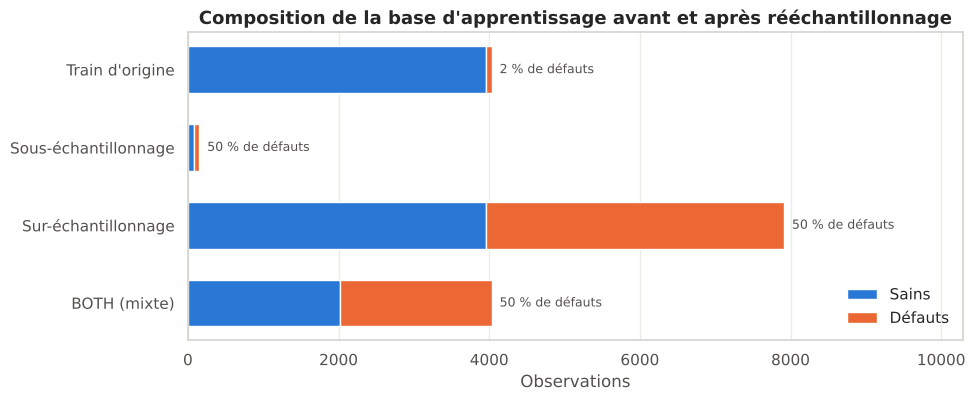

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(resampling_summary))
ax.barh(y, resampling_summary["sains"], color=BLUE, height=0.6, label="Sains")
ax.barh(y, resampling_summary["défauts"], left=resampling_summary["sains"], color=ORANGE, height=0.6, label="Défauts")
for i, (n, r) in enumerate(zip(resampling_summary["observations"], resampling_summary["taux de défaut (%)"])):
    ax.text(n, i, f"  {r:.0f} % de défauts", va="center", color=INK_2, fontsize=9)
ax.set_yticks(y, resampling_summary.index)
ax.invert_yaxis()
ax.set(title="Composition de la base d'apprentissage avant et après rééchantillonnage", xlabel="Observations",
       xlim=(0, resampling_summary["observations"].max() * 1.3))
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "03_reechantillonnage.png")
plt.show()

**Méthode retenue : BOTH (mixte)**. Elle évite les deux défauts extrêmes :
- le sous-échantillonnage seul ne garderait qu'une très petite base (on jette l'essentiel des clients sains) ;
- le sur-échantillonnage seul gonflerait la base en dupliquant des dizaines de fois chaque défaut, ce qui pousse au surapprentissage.

**Vérification de la distribution** : le rééchantillonnage ne doit modifier que la proportion de défauts, pas le profil des clients au sein de chaque classe. On le vérifie sur quelques variables : la répartition des classes parmi les défauts (et parmi les sains) doit rester proche avant et après.

In [21]:
chosen = resampled["BOTH (mixte)"]


def profile(d, col):
    return pd.crosstab(d[col], d["flag_defaut"], normalize="columns").mul(100).round(1)


checks = []
for col in ["Interdiction_cheque", "Segment", "Maturite"]:
    before, after = profile(train_bin, col), profile(chosen, col)
    for level in before.index:
        checks.append({"variable": col, "classe": level,
                       "défauts avant (%)": before.loc[level, 1], "défauts après (%)": after.get(1, pd.Series()).get(level, 0),
                       "sains avant (%)": before.loc[level, 0], "sains après (%)": after.get(0, pd.Series()).get(level, 0)})
pd.DataFrame(checks)

,variable,classe,défauts avant (%),défauts après (%),sains avant (%),sains après (%)
0,Interdiction_cheque,Non,80.3,81.0,98.0,98.0
1,Interdiction_cheque,Oui,19.7,19.0,2.0,2.0
2,Segment,Autres,10.5,11.3,7.0,7.2
3,Segment,"Private customer, universal (01)",3.9,4.7,7.4,8.1
4,Segment,Retail BRONZE (07),56.6,55.1,61.2,60.1
5,Segment,Retail GOLD (08),28.9,29.0,24.4,24.5
6,Maturite,]-∞ ; 9.50],57.9,60.0,35.0,35.2
7,Maturite,]15.50 ; +∞],31.6,30.5,38.8,38.4
8,Maturite,]9.50 ; 15.50],10.5,9.6,26.2,26.4


Les profils restent proches : le rééchantillonnage a changé le **poids** des défauts sans déformer leurs caractéristiques. Les petits écarts côté défauts viennent du tirage avec remise d'un petit nombre de défauts distincts. C'est la limite principale du rééchantillonnage : il ne crée **aucune information nouvelle**.

---
# Partie 3 — Sélection des variables pertinentes

## 13. Information Value (IV)

Pour chaque classe $i$ d'une variable :

$$\text{WOE}_i = \ln\left(\frac{\%\,\text{sains}_i}{\%\,\text{défauts}_i}\right) \qquad \text{IV} = \sum_i \left(\%\,\text{sains}_i - \%\,\text{défauts}_i\right) \times \text{WOE}_i$$

où $\%\,\text{sains}_i$ est la part des clients sains de la base qui tombent dans la classe $i$. Un WOE positif signale une classe **moins risquée** que la moyenne, un WOE négatif une classe **plus risquée**. Pour éviter un logarithme de zéro dans les classes sans défaut, on ajoute 0,5 à chaque effectif (correction de Laplace).

**Sur quelle base ?** L'IV est calculée sur la **base train d'origine**, pas sur la base rééchantillonnée : dupliquer des défauts n'ajoute pas d'information et rendrait l'IV artificiellement instable. Elle est recalculée sur la base **test** pour vérifier sa **stabilité**.

| IV | Pouvoir prédictif |
|---|---|
| < 0,02 | inutile |
| 0,02 – 0,1 | faible |
| 0,1 – 0,3 | moyen |
| 0,3 – 0,5 | fort |
| > 0,5 | suspect (à vérifier : fuite d'information ?) |

In [22]:
FEATURES = NUMERIC + CATEGORICAL


def woe_table(d: pd.DataFrame, col: str) -> pd.DataFrame:
    t = pd.crosstab(d[col], d["flag_defaut"]).reindex(columns=[0, 1], fill_value=0)
    t = t.reindex([b for b in BIN_ORDER[col] if b in t.index])   # classes dans l'ordre naturel
    t.columns = ["sains", "défauts"]
    t["effectif"] = t.sum(axis=1)
    t["% effectif"] = t["effectif"] / t["effectif"].sum() * 100
    t["taux de défaut (%)"] = t["défauts"] / t["effectif"] * 100
    good, bad = t["sains"] + 0.5, t["défauts"] + 0.5
    dist_good, dist_bad = good / good.sum(), bad / bad.sum()
    t["WOE"] = np.log(dist_good / dist_bad)
    t["contribution IV"] = (dist_good - dist_bad) * t["WOE"]
    return t


def power(iv: float) -> str:
    return ("inutile" if iv < 0.02 else "faible" if iv < 0.1 else "moyen" if iv < 0.3
            else "fort" if iv < 0.5 else "suspect")


woe_train = {c: woe_table(train_bin, c) for c in FEATURES}
iv = pd.DataFrame({
    "type": ["quantitative" if c in NUMERIC else "qualitative" for c in FEATURES],
    "classes": [len(woe_train[c]) for c in FEATURES],
    "IV train": [woe_train[c]["contribution IV"].sum() for c in FEATURES],
    "IV test": [woe_table(test_bin, c)["contribution IV"].sum() for c in FEATURES],
    "p-value χ² (train)": [chi2_contingency(pd.crosstab(train_bin[c], train_bin["flag_defaut"]))[1]
                           if train_bin[c].nunique() > 1 else 1.0 for c in FEATURES],
}, index=FEATURES)
iv["pouvoir prédictif"] = iv["IV train"].map(power)
ratio = iv["IV test"] / iv["IV train"]
iv["stabilité"] = np.where((iv["IV train"] >= IV_MIN) & (iv["IV test"] < IV_MIN), "non confirmée sur le test",
                           np.where((ratio < 0.5) | (ratio > 2), "instable", "stable"))
iv = iv.sort_values("IV train", ascending=False)
iv.round(4)

,type,classes,IV train,IV test,p-value χ² (train),pouvoir prédictif,stabilité
Solde_arrete,quantitative,4,1.5727,1.0024,0.0000,suspect,stable
Solde_moyen,quantitative,4,1.0578,0.5601,0.0000,suspect,stable
Interdiction_cheque,qualitative,2,0.4577,0.3781,0.0000,fort,stable
Type_revenu,qualitative,4,0.3138,0.6013,0.0000,fort,stable
Engagement,quantitative,3,0.3130,0.1433,0.0019,fort,instable
Maturite,quantitative,3,0.2591,0.3127,0.0001,moyen,stable
Segmentation_commerciale,qualitative,5,0.2318,0.4320,0.0002,moyen,stable
Age,quantitative,4,0.2296,0.4798,0.0002,moyen,instable
Age_relation,quantitative,3,0.2232,0.7674,0.0011,moyen,instable
Categorie_sociale,qualitative,5,0.2206,0.1721,0.0010,moyen,stable


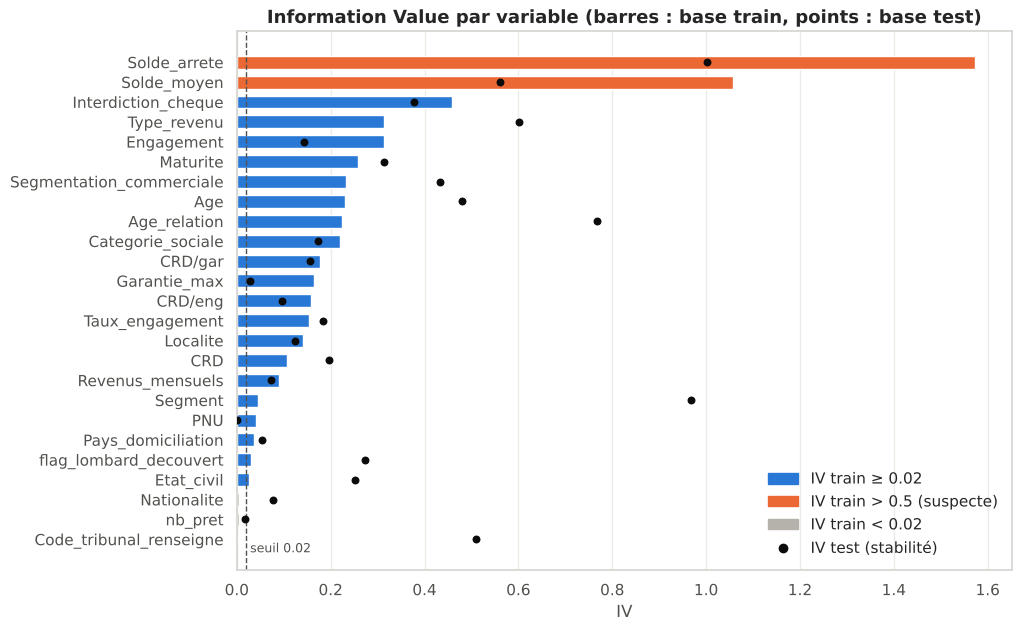

In [23]:
colors = [ORANGE if v >= IV_SUSPECT else (BLUE if v >= IV_MIN else GREY) for v in iv["IV train"]]
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(iv))
ax.barh(y, iv["IV train"], color=colors, height=0.65)
ax.scatter(iv["IV test"], y, color=INK, s=22, zorder=3)
ax.axvline(IV_MIN, color=INK_2, ls="--", lw=1)
ax.text(IV_MIN, len(iv) - 0.2, f" seuil {IV_MIN}", color=INK_2, fontsize=9, va="bottom")
ax.set_yticks(y, iv.index)
ax.invert_yaxis()
ax.set(title="Information Value par variable (barres : base train, points : base test)", xlabel="IV")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label=f"IV train ≥ {IV_MIN}"), Patch(color=ORANGE, label=f"IV train > {IV_SUSPECT} (suspecte)"),
                   Patch(color=GREY, label=f"IV train < {IV_MIN}"),
                   Line2D([], [], marker="o", color=INK, lw=0, label="IV test (stabilité)")],
          frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "04_information_value.png")
plt.show()

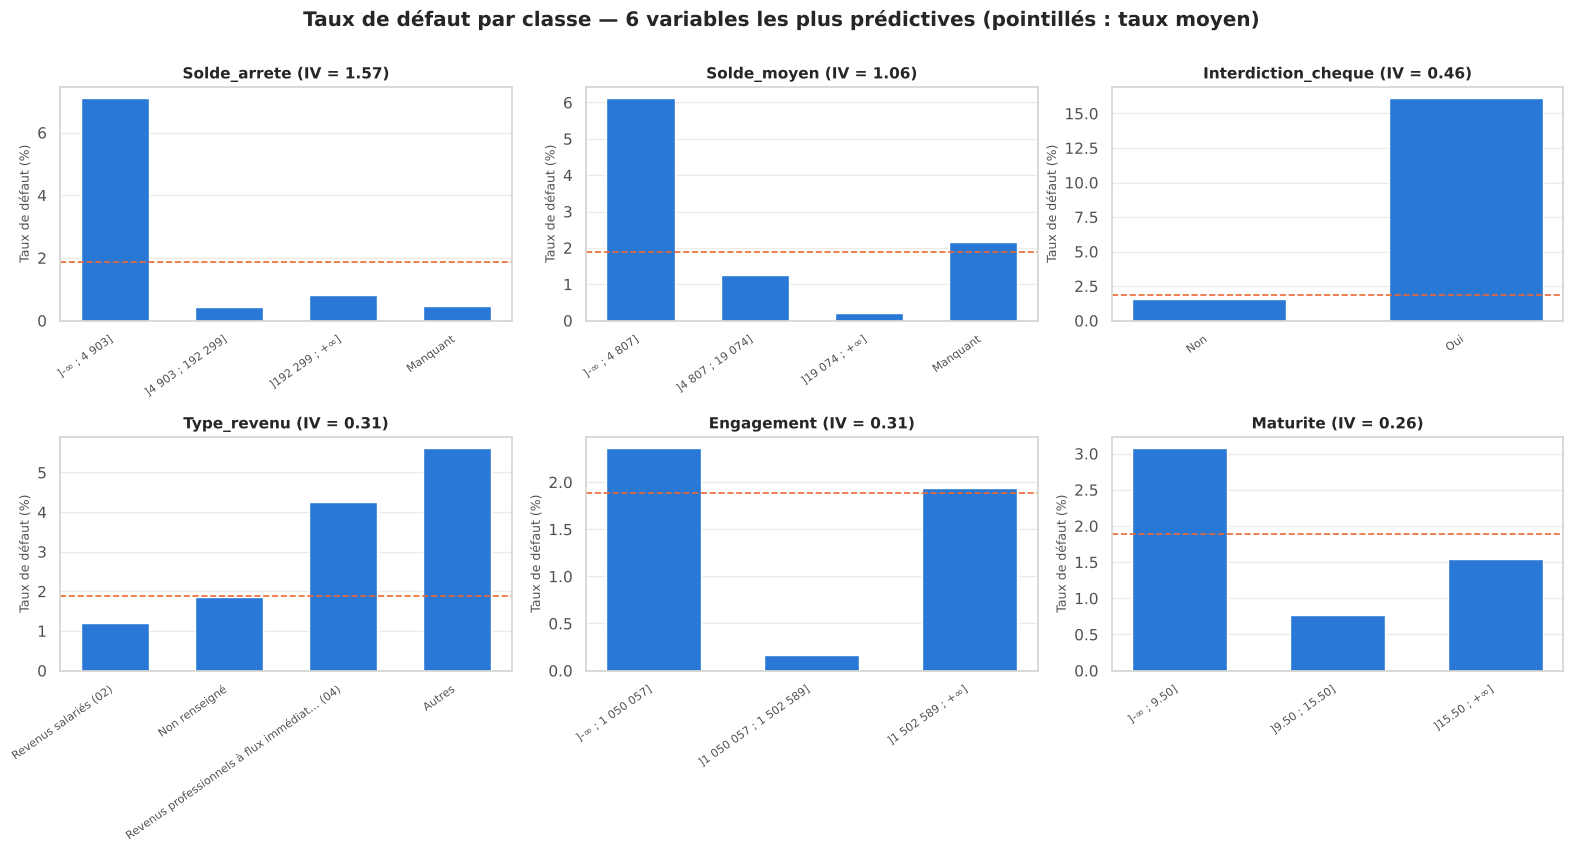

In [24]:
top = iv.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.flat, top):
    t = woe_train[col]
    ax.bar(range(len(t)), t["taux de défaut (%)"], color=BLUE, width=0.6)
    ax.axhline(train_bin["flag_defaut"].mean() * 100, color=ORANGE, ls="--", lw=1.2)
    ax.set_xticks(range(len(t)), [str(i) for i in t.index], rotation=35, ha="right", fontsize=8)
    ax.set_title(f"{col} (IV = {iv.loc[col, 'IV train']:.2f})", fontsize=11)
    ax.set_ylabel("Taux de défaut (%)", fontsize=9)
    ax.grid(axis="x", visible=False)
fig.suptitle("Taux de défaut par classe — 6 variables les plus prédictives (pointillés : taux moyen)",
             fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(FIGURES / "05_classes_top_variables.png")
plt.show()

**Points d'attention** :
- **Stabilité** : une variable dont l'IV s'effondre sur la base test (point noir loin de la barre) a une relation fragile avec le défaut, souvent parce qu'elle repose sur peu de défauts. Avec moins d'une centaine de défauts en apprentissage, toutes les IV sont estimées avec une incertitude importante.
- **IV suspecte (> 0,5)** : une IV très élevée peut révéler une fuite d'information, c'est-à-dire une variable qui est une **conséquence** du défaut plutôt qu'un facteur de risque observable avant. C'est notamment à vérifier pour `Interdiction_cheque` : une interdiction bancaire peut être prononcée **à cause** d'impayés. Il faut s'assurer auprès de la banque qu'elle est connue **avant** la période de mesure du défaut.

## 14. Étude de dépendance

Deux variables très liées apportent la même information. Les garder toutes les deux rendrait les coefficients de la régression logistique instables (multicolinéarité) et difficiles à interpréter. On mesure la liaison entre variables discrétisées par le **V de Cramér** :

$$V = \sqrt{\frac{\chi^2 / n}{\min(k - 1,\; l - 1)}}$$

où $k$ et $l$ sont les nombres de classes des deux variables. $V$ vaut 0 si les variables sont indépendantes et 1 si elles sont parfaitement liées. Au-delà de `CRAMER_MAX` = 0,5, les deux variables sont jugées redondantes : on garde celle qui a la plus forte IV.

**Attention au bloc de manquants.** Les ~30 % d'observations sans données sociodémographiques sont dans la classe « Non renseigné » / « Manquant » de **toutes** ces variables à la fois. Cette coïncidence suffit à créer un V de Cramér élevé entre des variables qui, par ailleurs, ne sont pas liées. On calcule donc le V de Cramér **sur les deux périmètres**, et la décision de redondance s'appuie sur le périmètre **hors bloc non renseigné**, qui mesure la vraie liaison entre les informations.

Observations du bloc non renseigné dans la base train : 1201 (30%)


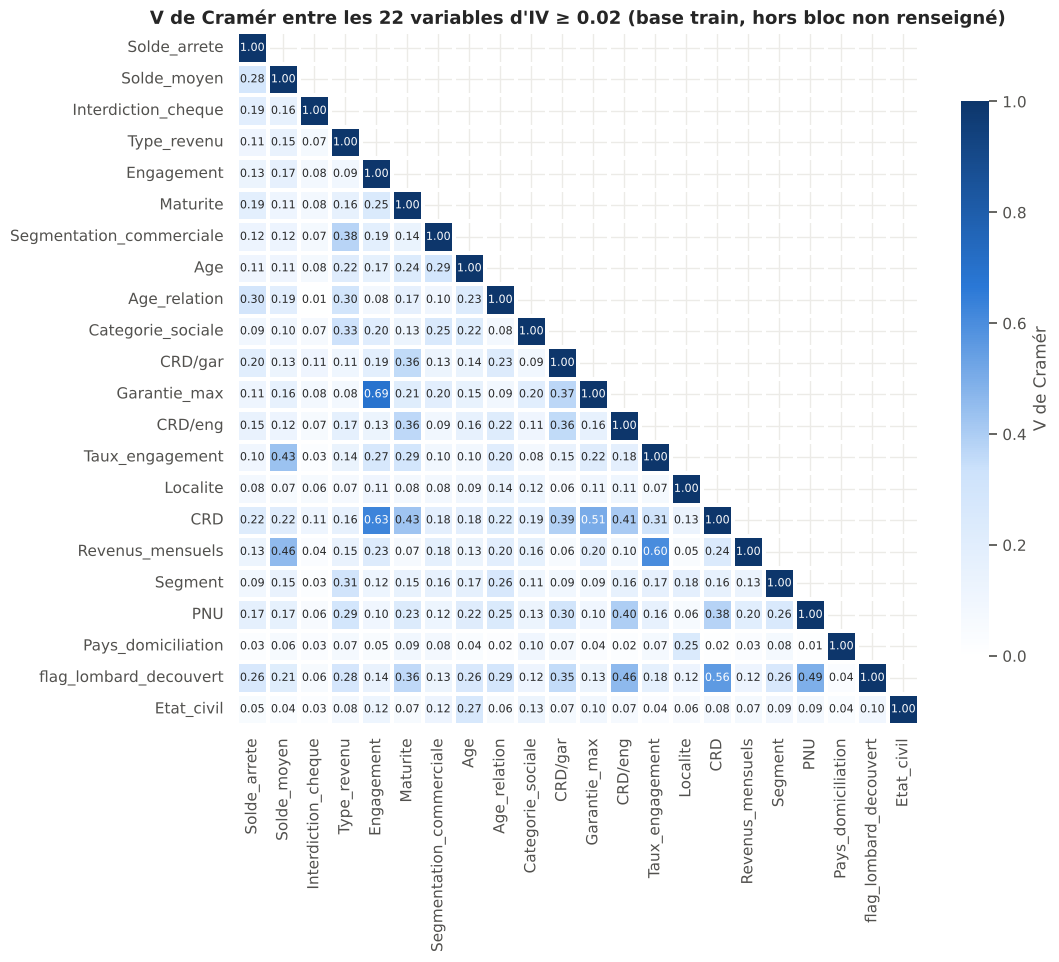

In [25]:
def cramers_v(a: pd.Series, b: pd.Series) -> float:
    table = pd.crosstab(a, b)
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / table.values.sum() / (min(table.shape) - 1)))


candidates = iv.index[iv["IV train"] >= IV_MIN].tolist()
in_block = train_bin["Pays_domiciliation"] == "Non renseigné"     # bloc sans données sociodémographiques
print(f"Observations du bloc non renseigné dans la base train : {in_block.sum()} ({in_block.mean():.0%})")

cramer_all = pd.DataFrame(np.eye(len(candidates)), index=candidates, columns=candidates)
cramer = cramer_all.copy()                                           # hors bloc : sert à la décision
for i, a in enumerate(candidates):
    for b in candidates[i + 1:]:
        cramer_all.loc[a, b] = cramer_all.loc[b, a] = cramers_v(train_bin[a], train_bin[b])
        cramer.loc[a, b] = cramer.loc[b, a] = cramers_v(train_bin.loc[~in_block, a], train_bin.loc[~in_block, b])

cmap = LinearSegmentedColormap.from_list("seq", ["#ffffff", "#cde2fb", BLUE, "#0d366b"])
mask = np.triu(np.ones_like(cramer, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cramer, mask=mask, annot=True, fmt=".2f", cmap=cmap, vmin=0, vmax=1, linewidths=1.5,
            linecolor="white", annot_kws={"size": 8}, cbar_kws={"label": "V de Cramér", "shrink": 0.8}, ax=ax)
ax.set_title(f"V de Cramér entre les {len(candidates)} variables d'IV ≥ {IV_MIN} (base train, hors bloc non renseigné)")
fig.savefig(FIGURES / "06_dependance_cramer.png")
plt.show()

In [26]:
upper = np.triu(np.ones_like(cramer, dtype=bool), k=1)
pairs = (cramer.where(upper).stack().rename("V de Cramér (hors bloc)").reset_index()
         .rename(columns={"level_0": "variable 1", "level_1": "variable 2"}))
pairs.insert(2, "V de Cramér (toute la base)",
             [cramer_all.loc[a, b] for a, b in zip(pairs["variable 1"], pairs["variable 2"])])
pairs = pairs.sort_values("V de Cramér (hors bloc)", ascending=False)
pairs["IV variable 1"] = pairs["variable 1"].map(iv["IV train"]).round(4)
pairs["IV variable 2"] = pairs["variable 2"].map(iv["IV train"]).round(4)
pairs["redondantes"] = np.where(pairs["V de Cramér (hors bloc)"] > CRAMER_MAX, "Oui", "Non")
print("Paires qui dépasseraient le seuil sur toute la base mais pas hors bloc (dépendance artificielle) :",
      int(((pairs["V de Cramér (toute la base)"] > CRAMER_MAX) & (pairs["redondantes"] == "Non")).sum()))
pairs.round(3).head(12)

Paires qui dépasseraient le seuil sur toute la base mais pas hors bloc (dépendance artificielle) : 71


,variable 1,variable 2,V de Cramér (toute la base),V de Cramér (hors bloc),IV variable 1,IV variable 2,redondantes
99,Engagement,Garantie_max,0.686,0.691,0.313,0.166,Oui
103,Engagement,CRD,0.631,0.626,0.313,0.108,Oui
302,Taux_engagement,Revenus_mensuels,0.603,0.603,0.154,0.091,Oui
350,CRD,flag_lombard_decouvert,0.592,0.560,0.108,0.031,Oui
257,Garantie_max,CRD,0.505,0.506,0.166,0.108,Oui
416,PNU,flag_lombard_decouvert,0.514,0.493,0.041,0.031,Non
284,CRD/eng,flag_lombard_decouvert,0.481,0.464,0.159,0.031,Non
38,Solde_moyen,Revenus_mensuels,0.466,0.458,1.058,0.091,Non
35,Solde_moyen,Taux_engagement,0.440,0.435,1.058,0.154,Non
125,Maturite,CRD,0.412,0.428,0.259,0.108,Non


## 15. Variables retenues

Règle de sélection, appliquée dans l'ordre décroissant d'IV :
1. on écarte les variables d'IV < 0,02 (non prédictives) ;
2. on écarte les variables dont le lien avec le défaut n'est **pas significatif** au test du χ² d'indépendance (p-value ≥ 5 %). Avec si peu de défauts, une IV faible peut n'être que du bruit : le test vérifie qu'elle est statistiquement distinguable de zéro ;
3. on parcourt les variables restantes de la plus forte à la plus faible IV, et on écarte une variable si elle est redondante (V de Cramér hors bloc > 0,5) avec une variable déjà retenue.

In [27]:
selected, decisions = [], {}
for var in iv.index:
    if iv.loc[var, "IV train"] < IV_MIN:
        decisions[var] = f"Écartée : IV < {IV_MIN}"
        continue
    if iv.loc[var, "p-value χ² (train)"] >= ALPHA:
        decisions[var] = f"Écartée : lien non significatif (p = {iv.loc[var, 'p-value χ² (train)']:.2f})"
        continue
    redundant_with = [s for s in selected if cramer.loc[var, s] > CRAMER_MAX]
    if redundant_with:
        decisions[var] = f"Écartée : redondante avec {redundant_with[0]} (V = {cramer.loc[var, redundant_with[0]]:.2f})"
    else:
        selected.append(var)
        decisions[var] = "Retenue" + (" — IV suspecte, à valider" if iv.loc[var, "IV train"] >= IV_SUSPECT else "")

iv["décision"] = pd.Series(decisions)
print(f"{len(selected)} variables retenues sur {len(FEATURES)} candidates :")
print(" • " + "\n • ".join(f"{v} (IV = {iv.loc[v, 'IV train']:.3f}, {iv.loc[v, 'pouvoir prédictif']})" for v in selected))
iv[["IV train", "IV test", "pouvoir prédictif", "stabilité", "décision"]].round(4)

14 variables retenues sur 25 candidates :
 • Solde_arrete (IV = 1.573, suspect)
 • Solde_moyen (IV = 1.058, suspect)
 • Interdiction_cheque (IV = 0.458, fort)
 • Type_revenu (IV = 0.314, fort)
 • Engagement (IV = 0.313, fort)
 • Maturite (IV = 0.259, moyen)
 • Segmentation_commerciale (IV = 0.232, moyen)
 • Age (IV = 0.230, moyen)
 • Age_relation (IV = 0.223, moyen)
 • Categorie_sociale (IV = 0.221, moyen)
 • CRD/gar (IV = 0.177, moyen)
 • CRD/eng (IV = 0.159, moyen)
 • Taux_engagement (IV = 0.154, moyen)
 • Localite (IV = 0.140, moyen)


,IV train,IV test,pouvoir prédictif,stabilité,décision
Solde_arrete,1.5727,1.0024,suspect,stable,"Retenue — IV suspecte, à valider"
Solde_moyen,1.0578,0.5601,suspect,stable,"Retenue — IV suspecte, à valider"
Interdiction_cheque,0.4577,0.3781,fort,stable,Retenue
Type_revenu,0.3138,0.6013,fort,stable,Retenue
Engagement,0.3130,0.1433,fort,instable,Retenue
Maturite,0.2591,0.3127,moyen,stable,Retenue
Segmentation_commerciale,0.2318,0.4320,moyen,stable,Retenue
Age,0.2296,0.4798,moyen,instable,Retenue
Age_relation,0.2232,0.7674,moyen,instable,Retenue
Categorie_sociale,0.2206,0.1721,moyen,stable,Retenue


---
# Partie 4 — Modélisation : régression logistique

## 16. Codage WOE

Chaque variable retenue est remplacée par le **WOE de sa classe** (calculé sur la base train d'origine, section 13). Ce codage :
- transforme toutes les variables, quantitatives comme qualitatives, en une seule colonne numérique ;
- met toutes les variables sur la même échelle (le logarithme d'un rapport de chances), d'où l'absence de normalisation nécessaire ;
- rend la relation avec le logit du défaut **linéaire** par construction.

Avec la convention $\text{WOE} = \ln(\%\,\text{sains} / \%\,\text{défauts})$, une classe à WOE élevé est **peu risquée**. Dans un modèle qui prédit la probabilité de **défaut**, tous les coefficients doivent donc être **négatifs** : un coefficient positif signale un problème (multicolinéarité, relation instable) et la variable doit être retirée.

In [28]:
WOE_MAP = {col: woe_train[col]["WOE"].to_dict() for col in FEATURES}


def woe_encode(binned: pd.DataFrame, variables: list[str]) -> pd.DataFrame:
    """Remplace chaque classe par son WOE (classe inconnue de la base train → 0, c'est-à-dire risque moyen)."""
    return pd.DataFrame({v: binned[v].map(WOE_MAP[v]).astype(float).fillna(0.0) for v in variables},
                        index=binned.index)


X_train, y_train = woe_encode(train_bin, selected), train_bin["flag_defaut"].values
X_test, y_test = woe_encode(test_bin, selected), test_bin["flag_defaut"].values
X_resampled, y_resampled = woe_encode(chosen, selected), chosen["flag_defaut"].values
print(f"Base train : {X_train.shape} | base test : {X_test.shape} | base rééchantillonnée : {X_resampled.shape}")
X_train.head()

Base train : (4033, 14) | base test : (1692, 14) | base rééchantillonnée : (4033, 14)


,Solde_arrete,Solde_moyen,Interdiction_cheque,Type_revenu,Engagement,Maturite,Segmentation_commerciale,Age,Age_relation,Categorie_sociale,CRD/gar,CRD/eng,Taux_engagement,Localite
0,-1.364635,-0.135915,0.204736,0.019292,-0.222731,-0.495737,0.37777,-0.709732,-0.413346,0.629466,-0.305877,-0.445328,-0.194142,-0.061428
1,-1.364635,-0.135915,0.204736,0.019292,-0.222731,-0.495737,0.37777,-0.709732,-0.413346,0.629466,-0.209492,-0.445328,-0.194142,-0.061428
2,-1.364635,-0.135915,0.204736,0.019292,-0.222731,-0.495737,0.37777,-0.709732,-0.413346,0.629466,-0.209492,-0.445328,-0.194142,-0.061428
3,-1.364635,-0.135915,0.204736,0.019292,-0.222731,-0.495737,0.37777,-0.709732,-0.413346,0.629466,-0.209492,-0.445328,-0.194142,-0.061428
4,1.487368,-0.135915,0.204736,0.019292,-0.026237,0.204596,0.37777,0.228311,-0.413346,0.629466,-0.305877,-0.445328,-0.194142,-0.061428


## 17. Sélection pas à pas des variables du modèle

Une régression logistique est d'abord ajustée sur la **base train d'origine** (non rééchantillonnée). Les tests de significativité y sont fiables. Sur la base rééchantillonnée, en revanche, chaque défaut apparaît en moyenne 26 fois : le logiciel croirait disposer de 2 000 défauts au lieu de 76, et toutes les p-values seraient faussement minuscules.

Procédure descendante (*backward*), répétée jusqu'à stabilité :
1. si une variable a un coefficient **positif** (signe incohérent), on retire celle qui a la plus grande p-value parmi elles ;
2. sinon, si une variable a une p-value > 5 % (test de Wald), on retire la moins significative ;
3. sinon, le modèle est stable.

In [29]:
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve


def fit_logit(X: pd.DataFrame, y: np.ndarray) -> tuple[LogisticRegression, pd.DataFrame]:
    """Régression logistique non pénalisée (C très grand) + écarts-types, z et p-values (test de Wald)."""
    model = LogisticRegression(C=1e10, solver="lbfgs", max_iter=5000).fit(X, y)
    design = np.column_stack([np.ones(len(X)), X.values])
    p = model.predict_proba(X)[:, 1]
    cov = np.linalg.pinv(design.T @ (design * (p * (1 - p))[:, None]))
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    se = np.sqrt(np.diag(cov))
    table = pd.DataFrame({"coefficient": beta, "écart-type": se, "z": beta / se,
                          "p-value": 2 * norm.sf(np.abs(beta / se))}, index=["constante"] + list(X.columns))
    return model, table


steps, current = [], list(selected)
while True:
    _, table = fit_logit(X_train[current], y_train)
    coefs = table.drop("constante")
    wrong_sign = coefs[coefs["coefficient"] > 0]
    if not wrong_sign.empty:
        drop, reason = wrong_sign["p-value"].idxmax(), "coefficient positif (signe incohérent)"
    elif coefs["p-value"].max() > ALPHA:
        drop, reason = coefs["p-value"].idxmax(), "non significative"
    else:
        break
    steps.append({"étape": len(steps) + 1, "variable retirée": drop, "motif": reason,
                  "coefficient": coefs.loc[drop, "coefficient"], "p-value": coefs.loc[drop, "p-value"]})
    current.remove(drop)

MODEL_VARS = current
stepwise = pd.DataFrame(steps)
print(f"{len(MODEL_VARS)} variables dans le modèle final : {', '.join(MODEL_VARS)}")
stepwise.round(4)

8 variables dans le modèle final : Solde_arrete, Solde_moyen, Interdiction_cheque, Type_revenu, Categorie_sociale, CRD/gar, Taux_engagement, Localite


,étape,variable retirée,motif,coefficient,p-value
0,1,Maturite,coefficient positif (signe incohérent),0.1185,0.6885
1,2,Segmentation_commerciale,non significative,-0.0436,0.8734
2,3,CRD/eng,non significative,-0.2379,0.4719
3,4,Age,non significative,-0.3248,0.2126
4,5,Engagement,non significative,-0.5876,0.1098
5,6,Age_relation,non significative,-0.5348,0.0706


## 18. Modèle final

Le modèle final est entraîné sur la **base d'apprentissage rééchantillonnée** (méthode BOTH, 50 % de défauts), avec les variables issues de la sélection pas à pas.

**Correction de la constante.** Sur une base à 50 % de défauts, le modèle « croit » que le défaut est fréquent : ses probabilités brutes sont fortement surestimées. Le rééchantillonnage ne modifie que la proportion de défauts, pas leurs caractéristiques. Seule la **constante** est donc biaisée, et on la corrige :

$$\beta_0^{\text{corrigé}} = \beta_0 - \ln\left(\frac{\tau_{\text{échantillon}} / (1 - \tau_{\text{échantillon}})}{\pi / (1 - \pi)}\right)$$

où $\tau_{\text{échantillon}} = 50\,\%$ et $\pi$ est le vrai taux de défaut de la base train.

In [30]:
final_model, coef_resampled = fit_logit(X_resampled[MODEL_VARS], y_resampled)
_, coef_train = fit_logit(X_train[MODEL_VARS], y_train)

pi = y_train.mean()
tau = y_resampled.mean()
offset_correction = np.log((tau / (1 - tau)) / (pi / (1 - pi)))
intercept = final_model.intercept_[0] - offset_correction
betas = pd.Series(final_model.coef_.ravel(), index=MODEL_VARS)


def predict_pd(X: pd.DataFrame) -> np.ndarray:
    """Probabilité de défaut calibrée (constante corrigée)."""
    return 1 / (1 + np.exp(-(intercept + X[MODEL_VARS].values @ betas.values)))


coefficients = pd.DataFrame({
    "coefficient (base rééchantillonnée)": np.r_[intercept, betas.values],
    "coefficient (base train d'origine)": coef_train["coefficient"].values,
    "p-value (base train d'origine)": coef_train["p-value"].values,
}, index=["constante (corrigée)"] + MODEL_VARS)
print(f"Taux de défaut train π = {pi:.4f} | taux de l'échantillon τ = {tau:.2f} | "
      f"correction de la constante = {offset_correction:.3f}")
coefficients.round(4)

Taux de défaut train π = 0.0188 | taux de l'échantillon τ = 0.50 | correction de la constante = 3.952


,coefficient (base rééchantillonnée),coefficient (base train d'origine),p-value (base train d'origine)
constante (corrigée),-3.9925,-4.0223,0.0000
Solde_arrete,-0.6728,-0.7463,0.0000
Solde_moyen,-0.6086,-0.6444,0.0001
Interdiction_cheque,-0.6209,-0.5772,0.0000
Type_revenu,-0.8858,-0.7700,0.0003
Categorie_sociale,-0.3232,-0.5578,0.0393
CRD/gar,-0.9944,-0.7764,0.0306
Taux_engagement,-1.0664,-1.1913,0.0017
Localite,-0.4239,-1.0532,0.0149


Les coefficients estimés sur la base rééchantillonnée et sur la base d'origine sont très proches : le rééchantillonnage a surtout déplacé la constante, ce que la correction compense. Tous les coefficients sont négatifs, comme attendu avec le codage WOE.

## 19. Performance sur la base test

Métriques de **discrimination** (le modèle classe-t-il les clients risqués au-dessus des autres ?) :
- **AUC** : probabilité qu'un client en défaut tiré au hasard ait une PD plus élevée qu'un client sain tiré au hasard (0,5 = hasard, 1 = parfait) ;
- **Gini** = 2 × AUC − 1, l'indicateur de référence en notation bancaire ;
- **KS** (Kolmogorov-Smirnov) : écart maximal entre les distributions de score des sains et des défauts.

Métrique de **calibrage** (les PD sont-elles au bon niveau ?) : PD moyenne prédite comparée au taux de défaut observé.

In [31]:
def performance(y: np.ndarray, pd_hat: np.ndarray) -> dict:
    fpr, tpr, _ = roc_curve(y, pd_hat)
    auc = roc_auc_score(y, pd_hat)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": np.max(tpr - fpr),
            "PD moyenne prédite (%)": pd_hat.mean() * 100, "taux de défaut observé (%)": y.mean() * 100}


pd_train, pd_test = predict_pd(X_train), predict_pd(X_test)

# Comparaisons : modèle sans rééchantillonnage, et modèle sans les variables de solde (IV suspecte)
plain_model = LogisticRegression(C=1e10, max_iter=5000).fit(X_train[MODEL_VARS], y_train)
no_balance = [v for v in MODEL_VARS if v not in ("Solde_arrete", "Solde_moyen")]
alt_model = LogisticRegression(C=1e10, max_iter=5000).fit(X_resampled[no_balance], y_resampled)

perf = pd.DataFrame({
    "Modèle final — train": performance(y_train, pd_train),
    "Modèle final — test": performance(y_test, pd_test),
    "Sans rééchantillonnage — test": performance(y_test, plain_model.predict_proba(X_test[MODEL_VARS])[:, 1]),
    "Sans variables de solde — test": {**performance(y_test, alt_model.predict_proba(X_test[no_balance])[:, 1]),
                                       "PD moyenne prédite (%)": np.nan},
}).T
perf.round(3)

,AUC,Gini,KS,PD moyenne prédite (%),taux de défaut observé (%)
Modèle final — train,0.892,0.785,0.677,1.821,1.884
Modèle final — test,0.811,0.622,0.543,1.815,2.423
Sans rééchantillonnage — test,0.788,0.577,0.523,1.838,2.423
Sans variables de solde — test,0.687,0.374,0.312,NaN,2.423


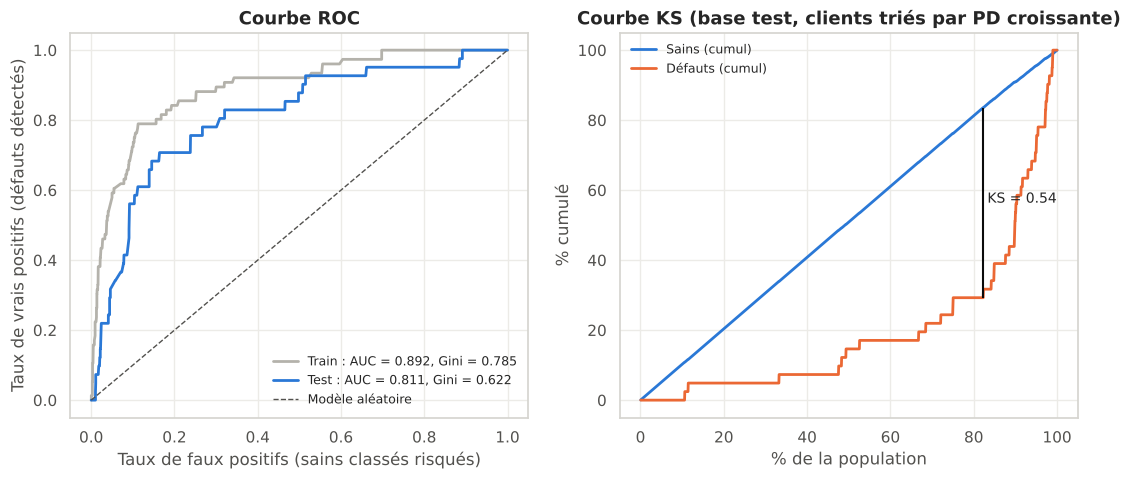

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for label, y, p, color in [("Train", y_train, pd_train, GREY), ("Test", y_test, pd_test, BLUE)]:
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{label} : AUC = {auc:.3f}, Gini = {2 * auc - 1:.3f}")
axes[0].plot([0, 1], [0, 1], color=INK_2, ls="--", lw=1, label="Modèle aléatoire")
axes[0].set(title="Courbe ROC", xlabel="Taux de faux positifs (sains classés risqués)",
            ylabel="Taux de vrais positifs (défauts détectés)")
axes[0].legend(frameon=False, loc="lower right", fontsize=9)

order = np.argsort(pd_test)
cum_bad = np.cumsum(y_test[order]) / y_test.sum()
cum_good = np.cumsum(1 - y_test[order]) / (1 - y_test).sum()
ks_idx = np.argmax(np.abs(cum_good - cum_bad))
x_axis = np.arange(1, len(order) + 1) / len(order) * 100
axes[1].plot(x_axis, cum_good * 100, color=BLUE, lw=2, label="Sains (cumul)")
axes[1].plot(x_axis, cum_bad * 100, color=ORANGE, lw=2, label="Défauts (cumul)")
axes[1].vlines(x_axis[ks_idx], cum_bad[ks_idx] * 100, cum_good[ks_idx] * 100, color=INK, lw=1.5)
axes[1].text(x_axis[ks_idx] + 1, (cum_bad[ks_idx] + cum_good[ks_idx]) * 50,
             f"KS = {abs(cum_good[ks_idx] - cum_bad[ks_idx]):.2f}", fontsize=10)
axes[1].set(title="Courbe KS (base test, clients triés par PD croissante)", xlabel="% de la population",
            ylabel="% cumulé")
axes[1].legend(frameon=False, loc="upper left", fontsize=9)
fig.savefig(FIGURES / "07_roc_ks.png")
plt.show()

**Lecture** :
- Un Gini au-delà de 0,5 est généralement jugé bon pour un modèle de notation de particuliers. L'écart entre train et test mesure le **surapprentissage**.
- Le modèle sans rééchantillonnage donne une AUC très proche : rééquilibrer les classes ne change pas le **classement** des clients par une régression logistique. Son intérêt est surtout la stabilité de l'estimation, et la correction de la constante restitue le bon niveau de PD.
- Le modèle **sans les variables de solde** mesure ce que le modèle perd si `Solde_arrete` et `Solde_moyen` étaient jugées inutilisables (fuite d'information possible, section 13). C'est l'information à présenter au métier pour décider.

## 20. Interprétation des coefficients

Pour comparer les variables entre elles, on mesure leur **poids dans le score** : l'écart de points entre la meilleure et la pire classe de la variable (section 21). Plus l'écart est grand, plus la variable peut faire varier la note d'un client.

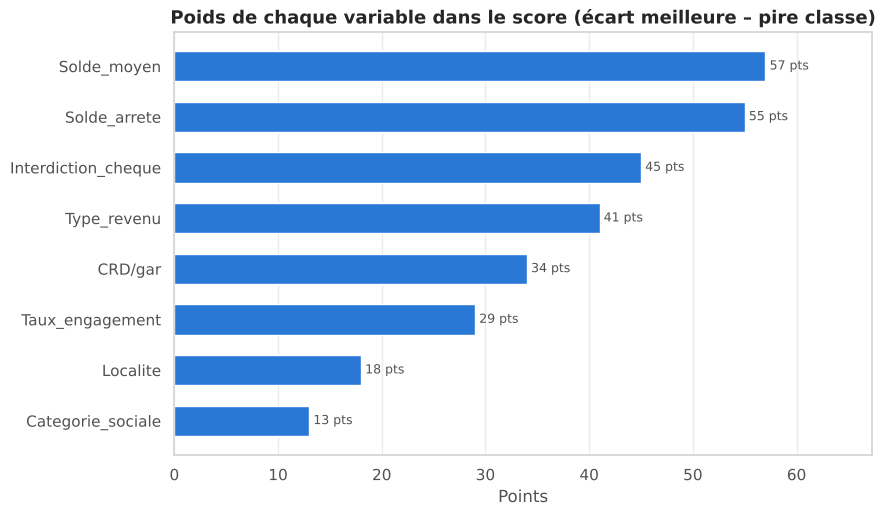

,coefficient,écart de points,poids relatif (%)
variable,,,
Solde_moyen,-0.609,57,19.5
Solde_arrete,-0.673,55,18.8
Interdiction_cheque,-0.621,45,15.4
Type_revenu,-0.886,41,14.0
CRD/gar,-0.994,34,11.6
Taux_engagement,-1.066,29,9.9
Localite,-0.424,18,6.2
Categorie_sociale,-0.323,13,4.5


In [33]:
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50      # +20 points = chances de remboursement doublées ; 600 points ↔ 50 sains pour 1 défaut
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
n_vars = len(MODEL_VARS)

rows = []
for var in MODEL_VARS:
    t = woe_train[var]
    for cls, w in t["WOE"].items():
        points = -factor * betas[var] * w + (offset - factor * intercept) / n_vars
        rows.append({"variable": var, "classe": cls, "effectif train": int(t.loc[cls, "effectif"]),
                     "taux de défaut train (%)": round(t.loc[cls, "taux de défaut (%)"], 2),
                     "WOE": round(w, 4), "coefficient": round(betas[var], 4), "points": int(round(points))})
scorecard = pd.DataFrame(rows)

weight = (scorecard.groupby("variable")["points"].agg(lambda p: p.max() - p.min())
          .rename("écart de points").sort_values(ascending=False))
importance = pd.DataFrame({"coefficient": betas.reindex(weight.index).round(3), "écart de points": weight,
                           "poids relatif (%)": (weight / weight.sum() * 100).round(1)})

fig, ax = plt.subplots(figsize=(9, 0.5 * len(weight) + 1.5))
bars = ax.barh(weight.index[::-1], weight.values[::-1], color=BLUE, height=0.6)
ax.bar_label(bars, fmt="%d pts", padding=3, color=INK_2, fontsize=9)
ax.set(title="Poids de chaque variable dans le score (écart meilleure – pire classe)", xlabel="Points",
       xlim=(0, weight.max() * 1.18))
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "08_importance_variables.png")
plt.show()
importance

Un coefficient s'interprète en **rapport de chances** : passer d'une classe à une autre dont le WOE est plus élevé d'une unité multiplie la cote du défaut ($P/(1-P)$) par $e^{\beta}$, une valeur inférieure à 1 puisque $\beta < 0$. Le tableau ci-dessous en donne une lecture directe, classe par classe.

## 21. Grille de notation (score)

Le score est construit selon la convention des cartes de score bancaires :

$$\text{Score} = \text{Offset} + \text{Facteur} \times \ln(\text{cote sains / défauts}), \quad \text{Facteur} = \frac{\text{PDO}}{\ln 2}, \quad \text{Offset} = 600 - \text{Facteur} \times \ln(50)$$

- 600 points correspondent à une cote de 50 clients sains pour 1 défaut (PD ≈ 2 %) ;
- tous les **20 points** (*PDO*, *points to double the odds*), la cote double, c'est-à-dire que le risque est environ divisé par deux.

Chaque classe de chaque variable reçoit un nombre de points ; le score d'un client est la **somme des points** de ses classes. Plus le score est élevé, plus le client est sûr.

In [34]:
def score(binned: pd.DataFrame) -> pd.Series:
    pts = {(r.variable, r.classe): r.points for r in scorecard.itertuples()}
    neutral = {v: int(round((offset - factor * intercept) / n_vars)) for v in MODEL_VARS}
    return sum(binned[v].map(lambda c, v=v: pts.get((v, c), neutral[v])) for v in MODEL_VARS)


train_score, test_score = score(train_bin), score(test_bin)
print(f"Score minimal possible : {scorecard.groupby('variable')['points'].min().sum()} | "
      f"maximal : {scorecard.groupby('variable')['points'].max().sum()}")
print(f"AUC du score sur la base test : {roc_auc_score(y_test, -test_score):.3f} "
      "(identique à celle de la PD : le score n'est qu'une transformation de la PD)")
scorecard

Score minimal possible : 452 | maximal : 744
AUC du score sur la base test : 0.811 (identique à celle de la PD : le score n'est qu'une transformation de la PD)


,variable,classe,effectif train,taux de défaut train (%),WOE,coefficient,points
0,Solde_arrete,]-∞ ; 4 903],844,7.11,-1.3646,-0.6728,49
1,Solde_arrete,]4 903 ; 192 299],2368,0.42,1.4874,-0.6728,104
2,Solde_arrete,]192 299 ; +∞],605,0.83,0.7660,-0.6728,90
3,Solde_arrete,Manquant,216,0.46,1.0405,-0.6728,95
4,Solde_moyen,]-∞ ; 4 807],604,6.13,-1.2101,-0.6086,54
5,Solde_moyen,]4 807 ; 19 074],949,1.26,0.3905,-0.6086,82
6,Solde_moyen,]19 074 ; +∞],1371,0.22,2.0417,-0.6086,111
7,Solde_moyen,Manquant,1109,2.16,-0.1359,-0.6086,73
8,Interdiction_cheque,Non,3940,1.55,0.2047,-0.6209,79
9,Interdiction_cheque,Oui,93,16.13,-2.3174,-0.6209,34


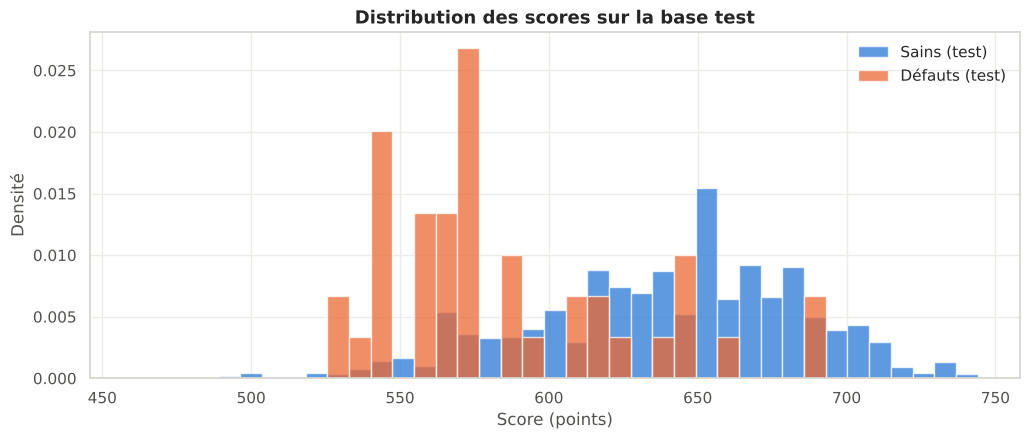

In [35]:
fig, ax = plt.subplots(figsize=(12, 4.5))
bins = np.linspace(min(train_score.min(), test_score.min()), max(train_score.max(), test_score.max()), 40)
ax.hist(test_score[y_test == 0], bins=bins, color=BLUE, alpha=0.75, density=True, label="Sains (test)")
ax.hist(test_score[y_test == 1], bins=bins, color=ORANGE, alpha=0.75, density=True, label="Défauts (test)")
ax.set(title="Distribution des scores sur la base test", xlabel="Score (points)", ylabel="Densité")
ax.legend(frameon=False)
fig.savefig(FIGURES / "09_distribution_scores.png")
plt.show()

## 22. Échelle PD finale (classes de notation)

Les clients sont regroupés en **classes de notation** (de A, la meilleure, à F). Chaque classe correspond à un intervalle de PD fixé à l'avance, croissant de façon géométrique, comme dans les *master scales* bancaires. On vérifie ensuite sur les deux bases que :
- le **taux de défaut observé augmente** d'une classe à l'autre (monotonie) ;
- aucune classe ne concentre une part excessive de la population ;
- la PD de la classe est cohérente avec les défauts observés.

**PD finale d'une classe avec marge de prudence.** Avec peu de défauts par classe, le taux observé est imprécis : 2 défauts sur 1 500 clients peuvent correspondre à un vrai taux bien plus élevé. Comme en pratique bancaire, la PD finale retient la valeur la plus prudente entre :
- la PD moyenne prédite par le modèle pour les clients de la classe (base train) ;
- la borne haute de l'intervalle de confiance à 95 % du taux de défaut observé dans la classe (intervalle de Jeffreys, adapté aux petits effectifs).

On impose enfin que la PD finale soit croissante de A à F. Une première version à 7 classes donnait la même PD finale à deux classes voisines (0,25–0,5 % et 0,5–1 %), qui ont donc été fusionnées : l'échelle compte **6 classes**.

**Back-testing sur la base test** : pour chaque classe, on vérifie par un test binomial si le nombre de défauts observés sur la base test est compatible avec la PD finale.

In [36]:
GRADES = ["A", "B", "C", "D", "E", "F"]
PD_BOUNDS = [0, 0.0025, 0.01, 0.02, 0.05, 0.15, 1]          # 0,25 % ; 1 % ; 2 % ; 5 % ; 15 %


def grade(pd_hat: np.ndarray) -> pd.Series:
    return pd.Series(pd.cut(pd_hat, PD_BOUNDS, labels=GRADES, include_lowest=True), dtype="category")


train_grade, test_grade = grade(pd_train), grade(pd_test)


def grade_table(grades, y, pd_hat, name):
    t = pd.DataFrame({"classe": grades.values, "y": y, "pd": pd_hat}).groupby("classe", observed=False).agg(
        effectif=("y", "size"), défauts=("y", "sum"), pd_moyenne=("pd", "mean"))
    t["% population"] = t["effectif"] / t["effectif"].sum() * 100
    t["taux de défaut observé (%)"] = t["défauts"] / t["effectif"] * 100
    t["PD moyenne prédite (%)"] = t.pop("pd_moyenne") * 100
    return t.add_prefix(f"{name} — ")


master = pd.DataFrame({
    "PD min (%)": [b * 100 for b in PD_BOUNDS[:-1]], "PD max (%)": [b * 100 for b in PD_BOUNDS[1:]],
}, index=pd.Index(GRADES, name="classe"))
master = master.join(grade_table(train_grade, y_train, pd_train, "Train")).join(
    grade_table(test_grade, y_test, pd_test, "Test"))
from scipy.stats import beta as beta_dist, binom

d, n = master["Train — défauts"], master["Train — effectif"]
master["borne haute 95 % du taux observé train (%)"] = np.where(
    n > 0, beta_dist.ppf(0.975, d + 0.5, n - d + 0.5) * 100, np.nan)
master["PD finale (%)"] = (master[["Train — PD moyenne prédite (%)", "borne haute 95 % du taux observé train (%)"]]
                           .max(axis=1).cummax())
pd_final = master["PD finale (%)"] / 100
n_test, d_test = master["Test — effectif"], master["Test — défauts"]
master["défauts test attendus"] = n_test * pd_final
master["p-value test binomial"] = [
    min(1.0, 2 * min(binom.cdf(k, m, q), binom.sf(k - 1, m, q))) if m > 0 else np.nan
    for k, m, q in zip(d_test, n_test, pd_final)]
master["back-testing"] = np.where(master["p-value test binomial"] >= 0.05, "conforme", "à surveiller")
master["score min"] = [train_score[(train_grade == g).values].min() if (train_grade == g).any() else np.nan for g in GRADES]
master["score max"] = [train_score[(train_grade == g).values].max() if (train_grade == g).any() else np.nan for g in GRADES]
master.round(2)

,PD min (%),PD max (%),Train — effectif,Train — défauts,Train — % population,Train — taux de défaut observé (%),Train — PD moyenne prédite (%),Test — effectif,Test — défauts,Test — % population,Test — taux de défaut observé (%),Test — PD moyenne prédite (%),borne haute 95 % du taux observé train (%),PD finale (%),défauts test attendus,p-value test binomial,back-testing,score min,score max
classe,,,,,,,,,,,,,,,,,,,
A,0.00,0.25,1496,2,37.09,0.13,0.12,580,3,34.28,0.52,0.12,0.43,0.43,2.48,0.90,conforme,659,744
B,0.25,1.00,1353,7,33.55,0.52,0.54,583,6,34.46,1.03,0.52,1.01,1.01,5.91,1.00,conforme,619,660
C,1.00,2.00,423,5,10.49,1.18,1.41,187,3,11.05,1.60,1.41,2.57,2.57,4.81,0.58,conforme,599,620
D,2.00,5.00,366,12,9.08,3.28,3.30,155,6,9.16,3.87,3.20,5.49,5.49,8.50,0.50,conforme,572,599
E,5.00,15.00,315,26,7.81,8.25,8.27,164,20,9.69,12.20,7.99,11.68,11.68,19.15,0.91,conforme,537,572
F,15.00,100.00,80,24,1.98,30.00,25.32,23,3,1.36,13.04,27.26,40.62,40.62,9.34,0.01,à surveiller,460,538


Taux de défaut observé croissant d'une classe à l'autre (test) : True
Classes conformes au back-testing : 5 / 6


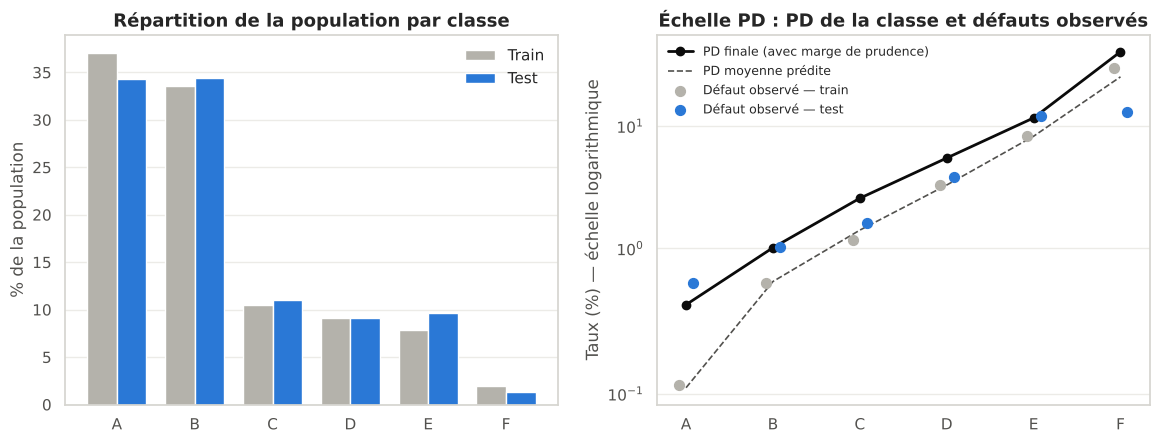

,PD finale (%),Test — effectif,Test — défauts,défauts test attendus,Test — taux de défaut observé (%),p-value test binomial,back-testing
classe,,,,,,,
A,0.428,580,3,2.484,0.517,0.904,conforme
B,1.013,583,6,5.906,1.029,1.000,conforme
C,2.571,187,3,4.808,1.604,0.579,conforme
D,5.486,155,6,8.503,3.871,0.497,conforme
E,11.677,164,20,19.150,12.195,0.908,conforme
F,40.616,23,3,9.342,13.043,0.009,à surveiller


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(GRADES))
width = 0.38
axes[0].bar(x - width / 2, master["Train — % population"], width, color=GREY, label="Train")
axes[0].bar(x + width / 2, master["Test — % population"], width, color=BLUE, label="Test")
axes[0].set(title="Répartition de la population par classe", ylabel="% de la population")
axes[0].set_xticks(x, GRADES)
axes[0].legend(frameon=False)

axes[1].plot(x, master["PD finale (%)"], color=INK, lw=2, marker="o", label="PD finale (avec marge de prudence)")
axes[1].plot(x, master["Train — PD moyenne prédite (%)"], color=INK_2, lw=1.2, ls="--", label="PD moyenne prédite")
axes[1].scatter(x - 0.08, master["Train — taux de défaut observé (%)"], color=GREY, s=50, zorder=3, label="Défaut observé — train")
axes[1].scatter(x + 0.08, master["Test — taux de défaut observé (%)"], color=BLUE, s=50, zorder=3, label="Défaut observé — test")
axes[1].set_yscale("symlog", linthresh=0.5)
axes[1].set_xticks(x, GRADES)
axes[1].set(title="Échelle PD : PD de la classe et défauts observés", ylabel="Taux (%) — échelle logarithmique")
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "10_echelle_pd.png")
plt.show()

observed = master["Test — taux de défaut observé (%)"].dropna()
print("Taux de défaut observé croissant d'une classe à l'autre (test) :",
      bool(observed[master.loc[observed.index, "Test — effectif"] > 0].is_monotonic_increasing))
print(f"Classes conformes au back-testing : {(master['back-testing'] == 'conforme').sum()} / {len(master)}")
master[["PD finale (%)", "Test — effectif", "Test — défauts", "défauts test attendus",
        "Test — taux de défaut observé (%)", "p-value test binomial", "back-testing"]].round(3)

**Lecture** :
- Les classes les mieux notées regroupent une large part des clients avec un risque faible, tandis que les dernières classes concentrent les défauts. Le taux de défaut observé croît de A à F sur les deux bases : l'échelle **discrimine** bien.
- Sur la base test, les meilleures classes font un peu plus de défauts que la PD prédite par le modèle, qui est donc légèrement optimiste pour les bons clients. La marge de prudence corrige cet écart, et le test binomial indique les classes encore à surveiller.
- La classe F est petite (environ 2 % de la population) : son taux observé est très instable d'une base à l'autre, et sa marge de prudence est donc large.
- Avec si peu de défauts, un back-testing sur un historique plus long (plusieurs générations de défauts) reste nécessaire pour valider définitivement l'échelle.

---
## Export Excel

Le classeur `outputs/resultats_SNI.xlsx` regroupe les livrables des parties 2 et 3 :

| Onglet | Contenu |
|---|---|
| `0_Lisez-moi` | description des onglets et paramètres utilisés |
| `1_Qualite_donnees` | synthèse des contrôles de la partie 1 |
| `2_Split_train_test` | effectifs et taux de défaut des bases train/test |
| `2_Base_train`, `2_Base_test` | bases traitées (valeurs imputées, classes, valeurs normalisées) |
| `2_Reechantillonnage` | comparaison des méthodes de rééchantillonnage |
| `2_Train_reechantillonne` | base d'apprentissage rééchantillonnée (méthode BOTH) |
| `3_IV_par_variable` | IV train/test, pouvoir prédictif, décision |
| `3_IV_detail_classes` | effectifs, taux de défaut, WOE et contribution à l'IV de chaque classe |
| `3_Dependance_Cramer` | matrice du V de Cramér hors bloc non renseigné (sert à la décision) |
| `3_Dependance_Cramer_tout` | matrice du V de Cramér sur toute la base (pour comparaison) |
| `3_Paires_dependance` | paires de variables triées par dépendance |
| `3_Variables_retenues` | variables retenues après IV et dépendance |
| `4_Selection_pas_a_pas` | variables retirées pendant la sélection du modèle |
| `4_Coefficients` | coefficients de la régression logistique |
| `4_Performance` | AUC, Gini, KS et calibrage (train, test, modèles de comparaison) |
| `5_Grille_score` | points attribués à chaque classe de chaque variable |
| `5_Echelle_PD` | classes de notation A à F, PD finale, back-testing |
| `5_Scores_test` | base test avec score, PD et classe de notation de chaque client |

In [38]:
def with_bins(base, binned, std):
    out = base.copy()
    for col in NUMERIC:
        out[f"{col}_classe"] = binned[col]
    return pd.concat([out, std], axis=1)


detail = pd.concat({c: woe_train[c] for c in iv.index}, names=["variable", "classe"]).reset_index()
readme = pd.DataFrame({"élément": [
    "Source", "Cible", "Unité statistique", "Doublons", "Séparation", "Imputation", "Normalisation",
    "Discrétisation", "Rééchantillonnage", "IV", "Dépendance", "Sélection", "Modèle", "Score et échelle PD"],
    "description": [
    f"{DATA_FILE.name}, onglet {SHEET} ({len(raw)} lignes)",
    f"flag_defaut = 1 si DPD 12M ≥ {SEUIL_DEFAUT} jours (taux global : {df.flag_defaut.mean():.2%})",
    "Client × année d'observation (2018–2021)",
    f"{exact_dup.sum()} doublons exacts supprimés",
    f"{int((1 - TEST_SIZE) * 100)} % / {int(TEST_SIZE * 100)} % par client, stratifiée sur le défaut (graine {RANDOM_STATE})",
    "Médiane train si < 5 % de manquants ; sinon classe « Manquant »",
    "Winsorisation 1 %–99 % puis centrage-réduction (colonnes *_std), paramètres appris sur le train",
    f"Arbre de décision : ≤ {MAX_BINS} classes, ≥ {MIN_BIN_SHARE:.0%} d'effectif par classe ; modalités < {RARE_SHARE:.0%} → « Autres »",
    f"Base train uniquement, méthode BOTH, taux de défaut visé {TAUX_CIBLE_RESAMPLING:.0%} ; base test non rééchantillonnée",
    "Calculée sur le train d'origine, contrôlée sur le test ; correction de Laplace (+0,5)",
    "V de Cramér entre variables discrétisées (base train), décision sur le périmètre hors bloc non renseigné",
    f"IV ≥ {IV_MIN}, lien significatif au χ² (p < {ALPHA}) et V de Cramér ≤ {CRAMER_MAX} avec les variables de plus forte IV",
    "Régression logistique sur WOE ; sélection descendante sur le train d'origine (signe et p-value), modèle final sur la base rééchantillonnée avec constante corrigée",
    f"Score : {BASE_SCORE} points pour une cote de {BASE_ODDS}:1, PDO = {PDO} ; échelle PD en 6 classes (A à F) avec marge de prudence"]})

sheets = {
    "0_Lisez-moi": readme,
    "1_Qualite_donnees": pd.concat([missing.reset_index(names="variable").assign(contrôle="Valeurs manquantes"),
                                    anomalies.rename(columns={"contrôle": "variable"}).assign(contrôle="Incohérence")]),
    "1_Plan_traitement": plan,
    "2_Split_train_test": split_summary.reset_index(names="base"),
    "2_Base_train": with_bins(train_base, train_bin, train_std),
    "2_Base_test": with_bins(test_base, test_bin, test_std),
    "2_Reechantillonnage": resampling_summary.reset_index(),
    "2_Train_reechantillonne": chosen,
    "3_IV_par_variable": iv.reset_index(names="variable").round(4),
    "3_IV_detail_classes": detail.round(4),
    "3_Dependance_Cramer": cramer.round(3).reset_index(names="variable (hors bloc)"),
    "3_Dependance_Cramer_tout": cramer_all.round(3).reset_index(names="variable (toute la base)"),
    "3_Paires_dependance": pairs.round(3),
    "3_Variables_retenues": iv.loc[selected, ["type", "classes", "IV train", "IV test", "pouvoir prédictif", "stabilité", "décision"]]
                              .reset_index(names="variable").round(4),
    "4_Selection_pas_a_pas": stepwise.round(4) if len(stepwise) else pd.DataFrame({"info": ["aucune variable retirée"]}),
    "4_Coefficients": coefficients.round(4).reset_index(names="variable"),
    "4_Performance": perf.round(4).reset_index(names="modèle / base"),
    "5_Grille_score": scorecard,
    "5_Echelle_PD": master.round(3).reset_index(),
    "5_Scores_test": test_bin[["id_tiers", "code_client", "annee", "flag_defaut"]].assign(
        score=test_score.values, PD=np.round(pd_test, 5), classe=test_grade.values),
}

output_file = OUTPUT_DIR / "resultats_SNI.xlsx"
with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    book = writer.book
    header = book.add_format({"bold": True, "bg_color": "#0d366b", "font_color": "white", "text_wrap": True,
                              "valign": "vcenter", "border": 1})
    for name, frame in sheets.items():
        frame.to_excel(writer, sheet_name=name, index=False)
        sheet = writer.sheets[name]
        for j, column in enumerate(frame.columns):
            sheet.write(0, j, str(column), header)
            width = min(max(len(str(column)), frame[column].astype(str).str.len().quantile(0.9) if len(frame) else 10) + 2, 60)
            sheet.set_column(j, j, width)
        sheet.freeze_panes(1, 0)
        sheet.autofilter(0, 0, len(frame), len(frame.columns) - 1)
    # mise en forme conditionnelle de la matrice de Cramér et des IV
    n = len(cramer)
    writer.sheets["3_Dependance_Cramer"].conditional_format(1, 1, n, n, {
        "type": "3_color_scale", "min_color": "#ffffff", "mid_color": "#9ec5f4", "max_color": "#0d366b",
        "min_type": "num", "min_value": 0, "mid_type": "num", "mid_value": 0.5, "max_type": "num", "max_value": 1})
    writer.sheets["3_IV_par_variable"].conditional_format(1, 3, len(iv), 3, {"type": "data_bar", "bar_color": BLUE})

print(f"Classeur enregistré : {output_file}")
for name, frame in sheets.items():
    print(f"  {name:<26} {frame.shape[0]:>5} lignes × {frame.shape[1]} colonnes")

Classeur enregistré : outputs/resultats_SNI.xlsx
  0_Lisez-moi                   14 lignes × 2 colonnes
  1_Qualite_donnees             26 lignes × 6 colonnes
  1_Plan_traitement             15 lignes × 3 colonnes
  2_Split_train_test             3 lignes × 6 colonnes
  2_Base_train                4033 lignes × 59 colonnes
  2_Base_test                 1692 lignes × 59 colonnes
  2_Reechantillonnage            4 lignes × 6 colonnes
  2_Train_reechantillonne     4033 lignes × 29 colonnes
  3_IV_par_variable             25 lignes × 9 colonnes
  3_IV_detail_classes           84 lignes × 9 colonnes
  3_Dependance_Cramer           22 lignes × 23 colonnes
  3_Dependance_Cramer_tout      22 lignes × 23 colonnes
  3_Paires_dependance          484 lignes × 7 colonnes
  3_Variables_retenues          14 lignes × 8 colonnes
  4_Selection_pas_a_pas          6 lignes × 5 colonnes
  4_Coefficients                 9 lignes × 4 colonnes
  4_Performance                  4 lignes × 6 colonnes
  5_Grille_

---
## Conclusion

**Partie 1 — Qualité des données.** La base contient 5 752 observations de 2 289 clients entre 2018 et 2021. Les contrôles ont mis en évidence 27 doublons exacts (supprimés), un bloc de 30 % d'observations sans aucune donnée sociodémographique, des manquants structurels (interdiction de chéquier, code tribunal) et plusieurs incohérences de codage (ratio CRD/garantie fixé à 1 pour des garanties nulles, dates de naissance par défaut, revenus nuls, indicateur qui n'en est pas un). La cible `flag_defaut` (DPD ≥ 90 jours) concerne environ 2 % des observations, et la variable `DPD 12M` qui la définit a été exclue des variables explicatives.

**Partie 2 — Traitement.** La séparation train/test a été faite **par client** et **avant** tout traitement, pour éviter toute fuite d'information. Les manquants rares ont été imputés par la médiane ; les manquants fréquents forment une classe à part, car ils sont informatifs. Les variables quantitatives ont été discrétisées par arbre de décision, et la base d'apprentissage a été rééquilibrée (méthode mixte) tandis que la base de test conserve la distribution réelle.

**Partie 3 — Sélection.** Les variables ont été classées par Information Value, avec un contrôle de stabilité sur la base test, puis filtrées pour éliminer les redondances (V de Cramér).

**Partie 4 — Modélisation.** Une régression logistique sur variables codées en WOE a été construite par sélection descendante, entraînée sur la base rééchantillonnée puis recalibrée (correction de la constante) pour retrouver le vrai niveau de risque. Ses performances sont mesurées sur une base test jamais utilisée (AUC, Gini, KS). Le modèle est traduit en **grille de score** (points par classe) et en **échelle de notation** de 6 classes, chacune associée à une PD.

**Limites.**
- Avec moins d'une centaine de défauts en apprentissage, les IV et les classes sont estimées avec une incertitude importante.
- La finesse de la discrétisation a été réduite après avoir constaté le surapprentissage d'une première version sur la base test. Pour une validation tout à fait indépendante, il faudrait un troisième échantillon (validation) ou une validation croisée par client sur la base train.
- Les classes issues de l'arbre ne sont pas contraintes à être **monotones** (par exemple, le taux de défaut d'`Engagement` monte et descend d'une classe à l'autre). Avant la modélisation, il faudra fusionner manuellement les classes adjacentes pour obtenir une évolution du risque monotone et interprétable (*coarse classing*).
- Les observations d'un même client sur plusieurs années ne sont pas indépendantes.
- Les variables à IV très élevée doivent être validées métier (risque de fuite d'information).

**Étapes suivantes** :
- valider métier les variables de solde (fuite d'information possible) et regrouper les classes non monotones ;
- back-tester l'échelle PD sur un historique plus long ;
- surveiller la stabilité de la population dans le temps (indice PSI) une fois le modèle en production.